# STELES PIPELINE 

## Part I - Basic CCD reduction, order extraction and rectification

by Felipe Navarete (LNA/MCTI)

*VERSION FOR DATA TAKEN AFTER MISSION 14 - 2026-01-28 OR LATER*

In [1]:
import glob
import json
import logging
import matplotlib.pyplot as plt
import numpy as np
import os
import time
import warnings
warnings.simplefilter('ignore', np.RankWarning)

from astropy.io import fits
from datetime import datetime, UTC

# local packages
import steles_pipeline_ccd as steles

#######################################################################################
print('functions were loaded.')

functions were loaded.


In [2]:
class STELES_Pipeline:

    def __init__(self, config):
        self.cfg = config
        self._setup_logging()
        
        self._identify_channel()
        self._get_channel_parameters()
        
        self._print_summary()
        
        self._setup_directories()
        self._validate_config()
        
        self.trace_poly_coeffs = None

    # =========================================================
    # Checkpointing System
    # =========================================================
        
    def _check_done(self, outputs):
        """Check if all output files exist"""
        return all(os.path.exists(f) for f in outputs)        
        
    # =========================================================
    # Setup
    # =========================================================
    def _setup_logging(self):
        
        logging.basicConfig(level=logging.INFO,
                            format='[%(levelname)s] %(message)s')
        self.log = logging.getLogger("STELES")
        
    def _create_directory(self, directory):
        
        if not os.path.isdir(directory):
            self.log.info(f"Creating new directory at {directory}")
            os.mkdir(directory)
        else:
            self.log.info(f"Directory '{directory}' already exists.")

    def _setup_directories(self):
        
        raw = self.cfg["raw_directory"]

        if not os.path.exists(raw):
            raise ValueError("<ERROR> Raw directory does not exist.")

        self.red       = os.path.join(raw, "RED/")
        self.trace_dir = os.path.join(self.red, "db_tracing/")

        self.trace_default_dir = os.path.join(f"./db/db_tracing_{self.channel}_2026-01/") 
        
        self.plot_dir = os.path.join(self.red, "plots")
        
        self._create_directory(self.red)
        self._create_directory(self.trace_dir)
        self._create_directory(self.plot_dir)
        
    def _validate_config(self):

        #required = ["raw_directory", "x_extract", "x_guesses"]
        required = ["raw_directory", "x_extract"]

        for key in required:
            if key not in self.cfg:
                raise ValueError(f"Missing required config key: {key}")

        if self.cfg["x_extract"][0] >= self.cfg["x_extract"][1]:
            raise ValueError("Invalid x_extract range")

        #if len(self.cfg["x_guesses"]) == 0:
        #    raise ValueError("x_guesses cannot be empty")
            
    def _fname(self, base, level="raw"):
        prefix = {
            "raw":     "",
            "merged":  "m_",
            "cleaned": "cm_"
        }[level]

        return prefix + base            
            
    def _timeit(self, func, name):
        t0 = time.time()
        func()
        dt = time.time() - t0
        self.log.info(f"{name} completed in {dt:.2f}s")
        
    
    def _get_bool(self, key, default=False):
        val = self.cfg.get(key, default)

        if isinstance(val, bool):
            return val

        if isinstance(val, str):
            return val.lower() in ["true", "1", "yes"]

        return bool(val)


    def _identify_channel(self):
        """ get channel based on the scientific data """
    
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: _identify_channel()")
            return
        
        self.log.info("Identifying channel")
        
        # check the master science frame
        try:
            sci_files  = [os.path.join(self.red, self.cfg["fileout_sci"] + ".fits")]
        # or the first raw science frame
        except:
            sci_files  = self._resolve("sci_list",  "sci_prefix")
        
        with fits.open(sci_files[0]) as hdul:
            steles_header = hdul[0].header
        
        try:
            self.channel = 'red' if steles_header['FPA'] == "RED" else 'blue'
        except:
            self.channel = 'red' if ( "RED" in steles_header['FIRMWARE'] ) else 'blue'
    
    def _get_channel_parameters(self):
        """
          get default parameters based on the channel - simplifies the config dictionary
        
            gain_per_amplifier (list): relative gain values for each amplifier to apply before merging them
            gain              (float): average gain of the detector (in e-/ADU)
            rdnoise           (float): read noise of the detector (in e-)
            transpose          (bool): transpose frame axis (True for Blue channel, False for Red channel)
            aperture_orders    (list): orders used for creating QC plot showing the apertures before extraction
            y_range            (list): pixel interval in the y-axis (dispersion) to extract the spectrum
            wavelength_file     (str): full path of the wavelength database for the corresponding channel
            x_guesses          (list): central position in the x-axis of each spectral order for each channel
        
        """

        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: get_channel_parameters()")
            return
        
        self.log.info(f"Retrieving parameters for the {self.channel} channel")
        
        self.gain_per_amplifier = [1.034, 1.0]        if self.channel == 'blue' else [1.035, 1.00]
        self.gain               = 2.23                if self.channel == 'blue' else 2.36
        self.rdnoise            = 6.38                if self.channel == 'blue' else 8.47
        self.transpose          = True                if self.channel == 'blue' else False
        self.y_range            = [0, 2047]           if self.channel == 'blue' else [500,3250]
        
        self.wavelength_file = f"./db/{self.channel}_wavelength_solution_2026-01.xlsx"
        
        # center of each order per channel
        if self.channel == 'blue':
            self.x_guesses = [ 56,  165,  270,  373,  473,  571,  665,  758,  848,  936, 1022, 1106, 1187, 1267, 1345, 1421, 1495, 1568, 1639, 1709, # 20
                             1776, 1843, 1907, 1971, 2034, 2095, 2155, 2213, 2271, 2327, 2383, 2436, 2489, 2541, 2593, 2643, 2691, 2740, 2787, 2834, # 40
                             2880, 2925, 2969, 3013, 3055, 3097, 3139, 3179, 3219, 3258, 3297, 3335, 3373, 3409, 3445, 3480, 3515, 3550, 3583, 3616, # 60
                             3650, 3682, 3713, 3745, 3776, 3806, ] # 66 - last with good wavelength solution
                             #3836, 3650, 3682, 3713, 3745, 3776, 3806, 3836, 3866, 3894, 3923, 3950, 3978, 4005, 4032]                              # 74
        else:
            self.x_guesses= [  72,  155,  235,  311,  384,  454,  521,  586,  648,  708,  765,  820,  873,  925,  975, 1023, 1069, 1115, 1158, 1200, # 20
                             1241, 1280, 1319, 1356, 1392, 1427, 1460, 1494, 1526, 1558, 1588, 1617, 1647, 1675, 1702, 1728, 1754, 1779, 1804, 1828, # 40
                             1851, 1874, 1895, 1917, 1938, 1958, 1978, 1997]                                                                   # 48

        self.n_orders = len(self.x_guesses)
        
        print_results = False
        if print_results:
            print("  gain_per_ampl=",self.gain_per_amplifier)
            print("           gain=",self.gain)
            print("        rdnoise=",self.rdnoise)
            print("      transpose=",self.transpose)
            print("        y_range=",self.y_range)
            print("       n_orders=",self.n_orders)
            print("      x_guesses=",self.x_guesses)
            print("wavelength_file=",self.wavelength_file)
 
    # =========================================================
    # Stage 1: Preprocessing
    # =========================================================

    def _resolve(self, list_key, prefix_key):
        files = []

        # --- list case ---
        if self.cfg.get(list_key):
            for name in self.cfg[list_key]:
                files.append(os.path.join(self.cfg["raw_directory"], name + ".fits"))

        # --- prefix case ---
        elif self.cfg.get(prefix_key):
            pattern = os.path.join(self.cfg["raw_directory"], self.cfg[prefix_key] + "*.fits")
            files.extend(sorted(glob.glob(pattern)))

        return files    
    
    def _collect_input_files(self):
        """
        Collect all raw files used in the pipeline (flat, sci, arc),
        returning FULL PATHS.
        """

        flat_files = self._resolve("flat_list", "flat_prefix")
        sci_files  = self._resolve("sci_list",  "sci_prefix")
        arc_files  = self._resolve("arc_list",  "arc_prefix")

        all_files = flat_files + sci_files + arc_files

        # Remove duplicates
        all_files = sorted(list(set(all_files)))

        if len(all_files) == 0:
            raise RuntimeError("No input files found for pipeline")

        self.log.info(f"Collected {len(all_files)} input files")

        return all_files
    
    def _collect_input_sci_files(self):
        """
        Collect all raw files used in the pipeline (flat, sci, arc),
        returning FULL PATHS.
        """

        sci_files  = self._resolve("sci_list",  "sci_prefix")

        # Remove duplicates
        all_files = sorted(list(set(sci_files)))

        if len(all_files) == 0:
            raise RuntimeError("No input files found for pipeline")

        self.log.info(f"Collected {len(all_files)} input science files")

        return all_files
    
    def _write_fits(self, data, header, output_path):
        hdu = fits.PrimaryHDU(data, header=header)
        hdul = fits.HDUList([hdu])
        hdul.writeto(output_path, overwrite=True)
        
    def merge_extensions(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: merge_extensions()")
            return

        self.log.info("Merging extensions")

        input_files = self._collect_input_files()
        
        #for file in input_files:
        n_files = len(input_files)

        for i, file in enumerate(input_files):

            filename = os.path.basename(file)

            self.log.info(f"[{i+1}/{n_files}] Merging {filename}")   
            
            filename = os.path.basename(file)
            output_filename = "m_" + filename
            output_path = os.path.join(self.red, output_filename)

            # --- Checkpoint ---
            if os.path.exists(output_path) and not self.cfg["overwrite"]:
                self.log.info(f"Skipping already merged: {output_filename}")
                continue
                
            # --- Run merge ---
            fits_out, hdr_out = steles.steles_merge_extensions(
                file,
                master_bias=None, #self.red,
                overscan_correction=True,
                #gain_per_amplifier=self.cfg["gain_per_amplifier"],
                gain_per_amplifier=self.gain_per_amplifier,
                remove_astrometry=True,
                show_results=False,
                figure_out=None
            )
            
            
            # --- Write output ---
            self._write_fits(fits_out, hdr_out, output_path)
            
    def cosmic_ray_clean(self):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: cosmic_ray_clean()")
            return
        
        self.log.info("Running cosmic ray cleaning")

        #input_files = self._collect_input_files()
        # apply only on science targets, not calibration files.
        input_files = self._collect_input_sci_files()
        

        #for raw_file in input_files:
        n_files = len(input_files)

        for i, raw_file in enumerate(input_files):

            filename = os.path.basename(raw_file)

            self.log.info(f"[{i+1}/{n_files}] CR cleaning {filename}")        
        
            merged_file = os.path.join(self.red, self._fname(filename, level="merged"))
            output_file = os.path.join(self.red, self._fname(filename, level="cleaned"))
            
            if not os.path.exists(merged_file):
                self.log.warning(f"Merged file not found, skipping: {merged_file}")
                continue

            if os.path.exists(output_file) and not self.cfg["overwrite"]:
                self.log.info(f"Skipping CR-cleaned file: {output_file}")
                continue

            #img, hdr = steles_red.steles_cosmicray_removal(
            img, hdr = steles.steles_cosmicray_removal(
                merged_file,
                #lacosmic_gain=self.cfg["gain"],
                #lacosmic_rdnoise=self.cfg["rdnoise"],
                lacosmic_gain=self.gain,
                lacosmic_rdnoise=self.rdnoise,
                show_plot=False,
                save_fits=False
            )

            hdr['ST_CRCLN'] = (True, "STELES cosmic ray clean")

            fits.PrimaryHDU(img, header=hdr).writeto(output_file, overwrite=True)
    
    # =========================================================
    # Stage 2: Calibration Preparation
    # =========================================================
    def scale_arcs(self):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: scale_arcs()")
            return
        
        outputs = [
            os.path.join(self.red, self.cfg["fileout_arc"] + ".fits")
        ]
        
        if self._check_done(outputs) and not self.cfg["overwrite"]:
            self.log.info("Skipping Scaling ThAr spectra creation")
            return
        
        self.log.info("Scaling ThAr spectra")

        #arc_files = ["m_" + f + ".fits" for f in self.cfg["arc_list"]]
        arc_files = [self._fname(f + ".fits", level="merged") for f in self.cfg["arc_list"]]
        
        # if you have more than one image, scale them
        if len(arc_files) > 1:
        
            scaled_arc = steles.scale_saturated_thar_spectrum(
                    self.red,
                    arc_files,
                    saturation_threshold=self.cfg["saturation_threshold_for_arc"],
                    return_hdu=True
                    #output_file=os.path.join(self.red, self.cfg["fileout_arc"] + ".fits")
                )     
        #otherwise just copy the single image
        else:
            print("COPY THE SINGLE ARC IMAGE AS MASTER_ARC")
        
        #if self.cfg.get("transpose", False):
        if self.transpose:
            scaled_arc = steles.transpose_frame(scaled_arc)

        # --- Write output ---
        self._write_fits(
            scaled_arc.data,
            scaled_arc.header, 
            os.path.join(self.red, self.cfg["fileout_arc"] + ".fits")
        )

    # =========================================================
    # Stage 3: Master Frames
    # =========================================================
    def _master_files_exist(self):
        files = [
            os.path.join(self.red, self.cfg["fileout_flat"] + ".fits"),
            os.path.join(self.red, self.cfg["fileout_sci"] + ".fits"),
            os.path.join(self.red, self.cfg["fileout_arc"] + ".fits"),
        ]
        return all(os.path.exists(f) for f in files)    

    def _load_frames(self, list_key=None, level='raw'):

        #prefix = self._get_prefix(list_key, prefix_key)

        # --- Case 1: explicit list ---
        if list_key and self.cfg.get(list_key):

            self.log.info(f"Loading frames from list: {list_key} (level={level})")

            #names = [prefix + f for f in self.cfg[list_key]]
            names = [self._fname(f, level=level) for f in self.cfg[list_key]]

            #frames, _ = steles_red.load_list_fits_data(
            frames, _ = steles.load_list_fits_data(
                self.red,
                names,
                extension=".fits",
                return_file_names=True
            )

            return frames
    
    def create_master_frames(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: create_master_frames()")
            return
        
        if self._master_files_exist() and not self.cfg["overwrite"]:
            self.log.info("Master frames exist - loading instead of recomputing")
            self.load_master_frames()
            return
        
        self.log.info("Creating master frames")

        def process(frames):
            #master = steles_red.process_frames(
            master = steles.process_frames(
                frames,
                sigma_clip=self.cfg["sigma_clip"],
                interpolate_bad_columns=self.cfg.get("interpolate_bad_columns", False),
                interpolate_bad_columns_sigma=self.cfg.get("interpolate_bad_columns_sigma", 2),
                interpolate_bad_columns_iterations=self.cfg.get("interpolate_bad_columns_iterations", 10),
            )

            #if self.cfg.get("transpose", False):
            if self.transpose:
                master = steles.transpose_frame(master)

            return master

        # --- Load frames flexibly ---
        flat_frames = self._load_frames("flat_list", level='merged') #, "flat_prefix")
        sci_frames  = self._load_frames("sci_list",  level="merged") #,  "sci_prefix")
        
        # --- Process ---
        master_flat = process(flat_frames)
        master_sci  = process(sci_frames)
        
        # --- Save ---
        self._write_fits(
            master_flat.data, 
            master_flat.header, 
            os.path.join(self.red, self.cfg["fileout_flat"] + ".fits")
        )

        self._write_fits(
            master_sci.data, 
            master_sci.header, 
            os.path.join(self.red, self.cfg["fileout_sci"] + ".fits")
        )

        # --- Load into memory ---
        #self.load_master_frames()

    # =========================================================
    # Stage 4: Load Data
    # =========================================================
    def load_master_frames(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: load_master_frames()")
            return
        
        self.log.info("Loading master frames")

        def load(name):
            #return steles_red.steles_read_file(os.path.join(self.red, name + ".fits"))
            return steles.steles_read_file(os.path.join(self.red, name + ".fits"))

        self.quartz_data, self.quartz_header, _ = load(self.cfg["fileout_flat"])
        self.arc_data, self.arc_header, _ = load(self.cfg["fileout_arc"])
        self.sci_data, self.sci_header, self.channel = load(self.cfg["fileout_sci"])

        
    # =========================================================
    # Stage 4b: Quality control data
    # =========================================================
        
    def quality_control_master_frames(self):
        
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: quality_control_master_frames()")
            return
        
        if not self.cfg.get("save_plots", True) and not self.cfg.get("show_plots", False):
            self.log.info("Skipping QC plots (disabled in config)")
            return

        self.log.info("Generating QC plots for master frames")

        quartz = self.quartz_data.copy()
        arc = self.arc_data.copy()
        sci = self.sci_data.copy()

        fig = plt.figure(figsize=(16, 8))
        ax1 = plt.subplot(131) # flat
        ax2 = plt.subplot(132) # arc
        ax3 = plt.subplot(133) # science
        
        # set titles
        x_title = 'columns <-> dispersion (pixel)' if self.channel == "blue" else 'columns <-> orders (pixel)'
        y_title = 'lines <-> orders (pixel)'       if self.channel == "blue" else 'lines <-> dispersion (pixel)'
        
        if self.transpose:
            def transpose_array(array):
                """ simple function to transpose the blue channel array"""
                # Transpose array
                array_T = array.copy()
                array_T = np.flip(array_T.T,axis=1)
                return array_T
            quartz = transpose_array(quartz)
            arc    = transpose_array(arc)
            sci    = transpose_array(sci)
            
        # --- Flat ---
        img1 = ax1.imshow(quartz,
                          vmin=0,
                          vmax=np.percentile(quartz, 95),
                          origin='lower',
                          aspect='auto')
        plt.colorbar(img1, ax=ax1, pad=0.01)
        ax1.set_title(self.quartz_header.get('OBJECT', 'FLAT'))
        ax1.set_xlabel(x_title)
        ax1.set_ylabel(y_title)

        # --- Arc ---
        img2 = ax2.imshow(arc,
                          vmin=0,
                          vmax=np.percentile(arc, 99),
                          origin='lower',
                          aspect='auto')
        plt.colorbar(img2, ax=ax2, pad=0.01)
        ax2.set_title(self.arc_header.get('OBJECT', 'ARC'))
        ax2.set_xlabel(x_title)
        ax2.set_ylabel(y_title)

        # --- Science ---
        img3 = ax3.imshow(sci,
                          vmin=0,
                          vmax=np.percentile(sci, 98),
                          origin='lower',
                          aspect='auto')
        plt.colorbar(img3, ax=ax3, pad=0.01)
        ax3.set_title(self.sci_header.get('OBJECT', 'SCIENCE'))
        ax3.set_xlabel(x_title)
        ax3.set_ylabel(y_title)

        plt.tight_layout()

        # --- Save ---
        if self.cfg.get("save_plots", True):
            out = os.path.join(
                self.plot_dir,
                self.cfg["fileout_sci"] + "_dataset.png"
            )
            plt.savefig(out, dpi=300)
            self.log.info(f"QC plot saved: {out}")

        # --- Show ---
        if self.cfg.get("show_plots", False):
            plt.show()
        else:
            plt.close()
        
    # =========================================================
    # Stage 5: Tracing
    # =========================================================
    
    def save_trace(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: save_trace()")
            return

        if self._trace_files_exist() and not self.cfg["overwrite"]:
            self.log.info("Skipping trace save (already exists)")
            return
        
        self.log.info("Saving trace coefficients")

        for i, coeffs in enumerate(self.trace_poly_coeffs):
            file_csv = os.path.join(self.trace_dir, f"poly_tracing_n{i+1:02d}.csv")

            steles.save_polyfits_tracing_csv(
                i + 1, coeffs, file_csv, show_messages=False
            )
            
    def trace_orders(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: trace_orders()")
            return

        if self._trace_files_exist() and not self.cfg["overwrite"]:
            self.log.info("Trace files found - loading existing solution")
            self.load_trace()
            return        

        self.log.info("Tracing spectral orders")

        #trace_data = self.sci_data
        trace_data = self.sci_data if self.cfg["trace_source"] == "sci" else self.quartz_data

        #n_orders = len(self.cfg["x_guesses"])
        #n_orders = len(self.x_guesses)

        trace_init = steles.read_master_tracing(
            trace_data,
            self.trace_default_dir,
            #self.cfg["trace_default_directory"],
            self.n_orders
        )
        if self.cfg["trace_source"] == "sci":
            output_file_prefix = os.path.join(self.plot_dir, f"{self.cfg['fileout_sci']}_order_retracing")
        else:
            output_file_prefix = os.path.join(self.plot_dir, f"{self.cfg['fileout_flat']}_order_retracing")
        
        self.trace_poly_coeffs = steles.refit_trace(
            trace_data,
            self.channel,
            trace_init,
            self.trace_default_dir,
            #self.cfg["trace_default_directory"],
            trace_window=15,
            trace_ndeg=4,
            skip_orders=self.cfg["refit_trace_skip_orders"],
            output_file_prefix=output_file_prefix
        )
        
        # save trace
        self.save_trace()

    def load_trace(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: load_trace()")
            return
        
        self.log.info("Loading trace coefficients from disk")

        #n_orders = len(self.cfg["x_guesses"])

        try:
            self.trace_poly_coeffs = steles.read_polyfits_tracing_csv(
                self.trace_dir,
                "poly_tracing_n",
                self.n_orders
            )
            self.log.info("Trace coefficients successfully loaded")

        except Exception as e:
            raise RuntimeError(f"Failed to load trace coefficients: {e}")    
            
    def _trace_files_exist(self):
        """ check if CSV files exist inside the 'trace_dir', if not, derived them """
        #n_orders = len(self.cfg["x_guesses"])

        for i in range(self.n_orders):
            file_csv = os.path.join(self.trace_dir, f"poly_tracing_n{i+1:02d}.csv")
            if not os.path.exists(file_csv):
                return False
        return True
    
    # =========================================================
    # Stage 5b: Quality control tracing
    # =========================================================
    def quality_control_tracing(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: quality_control_tracing()")
            return

        if not self.cfg.get("save_plots", True) and not self.cfg.get("show_plots", False):
            self.log.info("Skipping tracing QC plots (disabled)")
            return

        self.log.info("Generating tracing QC plot")

        trace_data = self.sci_data
        trace_poly_coeffs = self.trace_poly_coeffs

        # --- Prepare image ---
        plot_data = trace_data.copy()
        plot_data[plot_data <= 0] = 0.1

        #y_range_plot = self.cfg.get("y_range", [0, trace_data.shape[0]])
        y_range_plot = self.y_range
        
        
        y_axis = np.arange(y_range_plot[0], y_range_plot[1] + 1)

        fig = plt.figure(figsize=(15, 5))

        img = plt.imshow(
            np.log10(plot_data),
            origin="lower",
            aspect='auto',
            vmin=0,
            vmax=3,
            cmap="viridis"
        )

        intersections_found = False
        poly_last = None

        for n, coeffs in enumerate(trace_poly_coeffs):

            poly = np.poly1d(coeffs)

            # --- Intersection check ---
            if poly_last is not None:
                f_diff = poly - poly_last
                roots = np.roots(f_diff)
                roots = roots[np.isreal(roots)].real

                for y in roots:
                    x = poly(y)

                    if (0 < x < trace_data.shape[1]) and (0 < y < trace_data.shape[0]):
                        self.log.warning(
                            f"Trace intersection: orders {n} and {n+1} at (x={x:.2f}, y={y:.2f})"
                        )
                        intersections_found = True

            # --- Plot trace ---
            x_axis = poly(y_axis)
            mask = x_axis > 0

            plt.plot(x_axis[mask], y_axis[mask], alpha=0.5, lw=5)
            plt.plot(x_axis[mask], y_axis[mask], color='black', alpha=0.75, lw=0.5)

            poly_last = poly

        plt.xlim(0, trace_data.shape[1])
        plt.ylim(0, trace_data.shape[0])
        plt.xlabel("x-axis (along orders)")
        plt.ylabel("y-axis (dispersion)")
        plt.colorbar(img, pad=0.01, label='log(adu)')
        plt.tight_layout()

        # --- Save ---
        if self.cfg.get("save_plots", True):
            out = os.path.join(
                self.plot_dir,
                self.cfg["fileout_sci"] + "_tracing.png"
            )
            plt.savefig(out, dpi=600)
            self.log.info(f"Tracing QC plot saved: {out}")

        # --- Show ---
        if self.cfg.get("show_plots", False):
            plt.show()
        else:
            plt.close()

        # --- Optional: fail pipeline if bad ---
        if intersections_found and self.cfg.get("fail_on_trace_intersection", False):
            raise RuntimeError("Trace intersections detected - aborting pipeline.")            
            

    # =========================================================
    # Stage 6: Extraction
    # =========================================================
    def quality_control_apertures(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: quality_control_apertures()")
            return

        if not self.cfg.get("save_plots", True) and not self.cfg.get("show_plots", False):
            self.log.info("Skipping aperture QC plots (disabled)")
            return

        self.log.info("Generating aperture QC plots")

        trace_poly_coeffs = self.trace_poly_coeffs

        if trace_poly_coeffs is None:
            raise RuntimeError("Trace coefficients not available")

        plot_orders = self.cfg.get("aperture_orders", [])
        if len(plot_orders) == 0:
            raise ValueError("No aperture_orders defined in config")

        x_extract = self.cfg["x_extract"]
        #y_range_plot = self.cfg.get("y_range", [0, self.quartz_data.shape[0]])
        y_range_plot = self.y_range

        # --- Helper to prepare data ---
        def prepare(data):
            d = data.copy()
            d[d <= 0] = 0.1
            return np.log10(d)

        datasets = [
            ("flat", self.quartz_data, self.cfg["fileout_flat"]),
            ("arc",  self.arc_data,    self.cfg["fileout_arc"]),
            ("sci",  self.sci_data,    self.cfg["fileout_sci"]),
        ]

        for kind, data, name in datasets:

            plot_data = prepare(data)
            vmax = self.cfg.get("aperture_vmax", {}).get(kind, 4)

            fig = plt.figure(figsize=(18, 6))
            plt.suptitle(f"{kind.upper()} frame")

            n_plots = len(plot_orders)

            for i, order in enumerate(plot_orders):

                poly = np.poly1d(trace_poly_coeffs[order])
                y_axis = np.arange(y_range_plot[0], y_range_plot[1] + 1)
                x_axis = poly(y_axis)
                mask = x_axis > 0

                # --- dynamic window ---
                x_valid = x_axis[mask]
                x_min, x_max = x_valid.min(), x_valid.max()
                dx = x_max - x_min
                x_min -= 0.25 * dx
                x_max += 0.25 * dx

                x_min = max(0, x_min)
                x_max = min(data.shape[1], x_max)

                # --- plot ---
                ax = plt.subplot(1, n_plots, i + 1)

                img = ax.imshow(
                    plot_data,
                    origin="lower",
                    aspect="auto",
                    vmin=0,
                    vmax=vmax,
                    cmap="viridis"
                )

                # --- tracing ---
                ax.plot(x_axis[mask], y_axis[mask],
                        color='red', lw=1, label='Trace')

                # --- apertures ---
                ax.plot(x_axis[mask] + x_extract[0], y_axis[mask],
                        color='black', lw=1, label='Aperture')
                ax.plot(x_axis[mask] + x_extract[1], y_axis[mask],
                        color='black', lw=1)

                ax.set_xlim(x_min, x_max)
                ax.set_ylim(0, data.shape[0])
                ax.set_title(f"Order={order+1}")
                ax.set_xlabel("x-axis")

                if i == 0:
                    ax.set_ylabel("y-axis")
                    ax.legend()

            plt.colorbar(img, pad=0.01, label='log(adu)')
            plt.tight_layout()

            # --- Save ---
            if self.cfg.get("save_plots", True):
                out = os.path.join(self.plot_dir, name + "_aperture.png")
                plt.savefig(out, dpi=300)
                self.log.info(f"Aperture QC plot saved: {out}")

            # --- Show ---
            if self.cfg.get("show_plots", False):
                plt.show()
            else:
                plt.close()    
    
    def _linear_files_exist(self):
        files = [
            os.path.join(self.red, self.cfg["fileout_sci"]  + "_rectified.fits"),
            os.path.join(self.red, self.cfg["fileout_arc"]  + "_rectified.fits"),
            os.path.join(self.red, self.cfg["fileout_flat"] + "_rectified.fits"),
        ]
        return all(os.path.exists(f) for f in files)
    
    def load_linear_products(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: load_linear_products()")
            return
        self.log.info("Loading linearized products")

        def load(name):
            #return steles_red.steles_read_file(os.path.join(self.red, name))
            return steles.steles_read_file(os.path.join(self.red, name))

        self.sci_trace,  _, _ = load(self.cfg["fileout_sci"]  + "_rectified.fits")
        self.arc_trace,  _, _ = load(self.cfg["fileout_arc"]  + "_rectified.fits")
        self.flat_trace, _, _ = load(self.cfg["fileout_flat"] + "_rectified.fits")

        self.log.info("Linear products successfully loaded")
    
    
    def extract_orders(self):
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: extract_orders()")
            return

        if self._linear_files_exist() and not self.cfg["overwrite"]:
            self.log.info("Linear products exist - loading instead of recomputing")
            self.load_linear_products()
            return
        
        self.log.info("Extracting and linearizing orders")

        #n_orders = len(self.trace_poly_coeffs)

        flat_cube = []
        sci_cube  = []
        arc_cube  = []

        for order in range(self.n_orders):

            self.log.info(f"[{order+1}/{self.n_orders}] Extracting order")

            coeffs = self.trace_poly_coeffs[order] 

            flat = steles.linearize_trace(
                self.quartz_data, coeffs,
                x_left=self.cfg["x_extract"][0],
                x_right=self.cfg["x_extract"][1],
                #y_range=self.cfg["y_range"],
                y_range=self.y_range,
                flip_axis=True,
                show_plot=False,
                output_file=None
            )

            sci = steles.linearize_trace(
                self.sci_data, coeffs,
                x_left=self.cfg["x_extract"][0],
                x_right=self.cfg["x_extract"][1],
                #y_range=self.cfg["y_range"],
                y_range=self.y_range,
                flip_axis=True,
                show_plot=False,
                output_file=None
            )

            arc = steles.linearize_trace(
                self.arc_data, coeffs,
                x_left=self.cfg["x_extract"][0],
                x_right=self.cfg["x_extract"][1],
                #y_range=self.cfg["y_range"],
                y_range=self.y_range,
                flip_axis=True,
                show_plot=False,
                output_file=None
            )

            flat_cube.append(flat)
            sci_cube.append(sci)
            arc_cube.append(arc)

        flat_cube = np.array(flat_cube)
        sci_cube = np.array(sci_cube)
        arc_cube = np.array(arc_cube)

        # Save outputs
        self._save_cube(flat_cube, self.quartz_header, self.cfg["fileout_flat"] + "_rectified.fits")
        self._save_cube(sci_cube,  self.sci_header,    self.cfg["fileout_sci"]  + "_rectified.fits")
        self._save_cube(arc_cube,  self.arc_header,    self.cfg["fileout_arc"]  + "_rectified.fits")

    def _save_cube(self, data, header, filename):
        hdr = header.copy()
        hdr['ST_TRACE'] = True
        hdr['ST_LINEA'] = True
        
        # --- Write output ---
        self._write_fits(
            data,
            hdr, 
            os.path.join(self.red, filename)
        )
        

    # =========================================================
    # Report system
    # =========================================================
    def save_report(self):
        
        if self._get_bool("dry_run"):
            self.log.info(f"[DRY RUN] Would execute: save_report()")
            return

        report = {
            #"timestamp": datetime.utcnow().isoformat(),
            "timestamp": datetime.now(UTC).isoformat(),
            "raw_directory": self.cfg["raw_directory"],
            "channel": self.channel,
            "parameters": self.cfg,
            "outputs": {
                "science_linear": os.path.join(self.red, self.cfg["fileout_sci"]  + "_rectified.fits"),
                "arc_linear":     os.path.join(self.red, self.cfg["fileout_arc"]  + "_rectified.fits"),
                "flat_linear":    os.path.join(self.red, self.cfg["fileout_flat"] + "_rectified.fits"),
            },
            "summary": {
                "n_orders": self.n_orders,
                "status": "SUCCESS"
            }
        }

        
        
        report_name = f"steles_pipeline_report_partI_{self.channel}_{self.cfg['fileout_sci']}"
        
        # --- JSON ---
        json_file = os.path.join(self.red, report_name + ".json")
        
        # --- HTML ---
        html_file = os.path.join(self.red, report_name + ".html")

        
        with open(json_file, "w") as f:
            json.dump(report, f, indent=4)

        self.log.info(f"JSON report saved: {json_file}")

        self._generate_html_report(report, html_file)

        self.log.info(f"HTML report saved: {html_file}")

        # --- Optional: auto-open ---
        if self.cfg.get("open_report", False):
            import webbrowser
            webbrowser.open(html_file)        
        
    def _generate_html_report(self, report, html_file):

        def fmt_dict(d):
            return "<br>".join([f"<b>{k}</b>: {v}" for k, v in d.items()])

        html = f"""
        <html>
        <head>
            <title>STELES Pipeline Report</title>
            <style>
                body {{
                    font-family: Arial, sans-serif;
                    margin: 40px;
                    background-color: #f5f5f5;
                }}
                h1, h2 {{
                    color: #2c3e50;
                }}
                .section {{
                    background: white;
                    padding: 20px;
                    margin-bottom: 20px;
                    border-radius: 8px;
                    box-shadow: 0 2px 5px rgba(0,0,0,0.1);
                }}
                .code {{
                    background: #ecf0f1;
                    padding: 10px;
                    border-radius: 5px;
                    font-family: monospace;
                }}
                img {{
                    max-width: 100%;
                    border: 1px solid #ccc;
                    margin-top: 10px;
                }}
            </style>
        </head>

        <body>

        <h1>STELES Pipeline Report</h1>

        <div class="section">
            <h2>General Information</h2>
            <p><b>Timestamp:</b> {report['timestamp']}</p>
            <p><b>Raw Directory:</b> {report['raw_directory']}</p>
            <p><b>Channel:</b> {report['channel']}</p>
        </div>

        <div class="section">
            <h2>Parameters</h2>
            <div class="code">
                {fmt_dict(report['parameters'])}
            </div>
        </div>

        <div class="section">
            <h2>Outputs</h2>
            <div class="code">
                {fmt_dict(report['outputs'])}
            </div>
        </div>
        """

        # --- Add QC plots if they exist ---
        qc_plots = [
            self.cfg["fileout_sci"] + "_dataset.png",
            self.cfg["fileout_sci"] + "_tracing.png",
            self.cfg["fileout_sci"] + "_aperture.png",
            self.cfg["fileout_flat"] + "_aperture.png",
            self.cfg["fileout_arc"] + "_aperture.png",
        ]

        html += '<div class="section"><h2>Quality Control Plots</h2>'

        for plot in qc_plots:
            plot_path = os.path.join(self.plot_dir, plot)
            if os.path.exists(plot_path):
                rel_path = os.path.relpath(plot_path, self.red)
                html += f"<h3>{plot}</h3><img src='{rel_path}'>"

        html += "</div></body></html>"

        with open(html_file, "w") as f:
            f.write(html)        
        
    # =========================================================
    # Run Full Pipeline
    # =========================================================
        
    def _print_summary(self):
        self.log.info("")
        self.log.info("==== STELES PIPELINE CONFIG ====")
        # values from _get_channel_parameters
        self.log.info(f"channel: {self.channel}")
        self.log.info(f"n_orders: {self.n_orders}")
        self.log.info(f"gain_per_amplifier: {self.gain_per_amplifier}")
        self.log.info(f"gain: {self.gain}")
        self.log.info(f"rdnoise: {self.rdnoise}")
        self.log.info(f"transpose: {self.transpose}")
        self.log.info(f"y_range: {self.y_range}")
        self.log.info(f"x_guesses: {self.x_guesses}")
        self.log.info(f"wavelength_file: {self.wavelength_file}")
        #
        for k, v in self.cfg.items():
            self.log.info(f"{k}: {v}")
        self.log.info("================================")   
        self.log.info("")
        
    def _get_stages(self):
        stages = self.cfg.get("run_stages_partI", "all")

        # --- Case 1: "all" ---
        if isinstance(stages, str):
            if stages.lower() == "all":
                return {"all"}
            else:
                return {stages.lower()}

        # --- Case 2: list ---
        if isinstance(stages, (list, tuple)):
            return {s.lower() for s in stages}

        raise ValueError("run_stages must be 'all' or a list of stage names")        
        
    def run(self):
        #
        #if self.cfg.get("dry_run", False):
        if self._get_bool("dry_run"):
            self.log.info("DRY RUN MODE - no files will be written")     
            

        stages = self._get_stages()
        
        def run_stage(name):
            return "all" in stages or name in stages

        #
        if run_stage("merge"):
            self._timeit(self.merge_extensions, "Merge Extensions")
        if run_stage("cr"):
            self._timeit(self.cosmic_ray_clean, "Cosmic Ray Cleaning")
        if run_stage("arcs"):
            self._timeit(self.scale_arcs, "Scale Arcs")
        if run_stage("masters"):
            self._timeit(self.create_master_frames, "Create Master Frames")
            self.load_master_frames()
            self.quality_control_master_frames()
        #
        if run_stage("trace"):
            self._timeit(self.trace_orders, "Trace Orders")
            #self.save_trace()
            self.quality_control_tracing()
        #
        if run_stage("extract"):
            self.quality_control_apertures()
            self._timeit(self.extract_orders, "Extract Orders")
        #
        self.save_report()
        #
        self.log.info("Pipeline completed successfully.")

print("DONE")     

DONE


In [3]:
config_blue = {
    # =========================================================
    # General execution control
    # =========================================================
    "dry_run": False,
    "run_stages_partI":  ["all"],   # ['all'] OR provide a list of stages ["merge", "cr", "masters", "trace", "extract"]
    "run_stages_partII": ["all"],   # ['all'] OR provide a list of stages ["wave", "distortion", "apply", "blaze", "extract"]
    # =========================================================
    # PART I
    # =========================================================
    # Input / Output
    "raw_directory":  "D:/SOAR/Steles/2026-01-29_blue/", # set full path contaninig the raw data
    "save_plots":     True,
    "show_plots":     False,                             # important for batch mode
    # name of input files for flats, science and arcs
    "flat_list": ["flat_isb_3000mas_20260128_0033", "flat_isb_3000mas_20260128_0034", "flat_isb_3000mas_20260128_0035"],
    "sci_list":  ["sci_0054"],
    "arc_list":  ["thar_600mas_0013", "thar_600mas_0014"], # 1-sec and 60-sec ThAr exposure
    # name of master frames (stored in the <RED> directory)
    "fileout_flat": "master_flat",
    "fileout_sci":  "master_HR1996_600mas",
    "fileout_arc":  "master_ThAr_600mas",
    # arc scaling parameters
    "saturation_threshold_for_arc": 40000,
    # Tracing parameters
    "trace_source": "sci",    # "sci" or flat", default='sci'
    "refit_trace_skip_orders": [None],
    "sigma_clip": 5,
    "fail_on_trace_intersection": False,  # or True for strict mode
    # QC visualization parameters
    "aperture_orders": [0, 14, 29, 44, 59],
    "aperture_vmax": {"flat": 4.0, "arc": 3.5, "sci": 4.0},
    # Extracting parameters
    "x_extract": [-6,+18],  # blue 2026-01-28
    # =========================================================
    # PART II
    # =========================================================
    "window_fit_peak": 11,           # pixel window for peak refinement
    "max_fwhm_threshold": 10.0,      # exclude peaks broader than this threshold (in pixels) 
    "wavelength_pixel_offset": -2,   # offset the reference wavelength peak lines by a number of pixels (helps improving the wavelength solution)  
    "wavesolution_ndeg": 3,          # polynomial degree
    "wavesolution_niter": 3,         # number of iterations to refine wavelength solution
    "wavesolution_rms_threshold": 2.0, # sigma-threshold for removing lines from the wavelength solution
    # =========================================================
    # Spatial distortion parameters
    # =========================================================
    "ndeg_distortion": 2,         # polynomial degree for distortion
    "n_pix_step": 1,              # sampling along spatial axis
    # line filtering
    "saturation_threshold_for_spatial_distortion": 1000000,
    "sigma_threshold": 3.0,
    # fitting robustness
    "fitting_sigma_threshold": 3.0,
    "fitting_niter": 3,
    "distortion_sigma_init": 3.0,
    "distortion_sigma_min": 1.0,
    "distortion_sigma_step": 0.5,
    # QC visualization parameters
    "wave_pixel_reference": [2, 1024, 2045],  # typical for 2048 pix detector
    "spectral_pixel_limits": [1500, 2000],
    # =========================================================
    # Blaze function parameters
    # =========================================================
    "blaze_mode": "simple", # "simple" or "continuum"
    "blaze_min_deg": 15,
    "blaze_max_deg": 55,
    "blaze_sigma": 5,
    "blaze_ncols": 7,
    "qc_blaze_n_panels": 10,
    # =========================================================
    # Optional behavior
    # =========================================================
    "overwrite": True,   # overwrite existing products
}

config_red = {
    # =========================================================
    # General execution control
    # =========================================================
    "dry_run": False,
    "run_stages_partI":  ["all"],   # ['all'] OR provide a list of stages ["merge", "cr", "masters", "trace", "extract"]
    "run_stages_partII": ["all"],   # ['all'] OR provide a list of stages ["wave", "distortion", "apply", "blaze", "extract"]
    # =========================================================
    # PART I
    # =========================================================
    # Input / Output
    "raw_directory":  "D:/SOAR/Steles/2026-01-29_red/", # set full path contaninig the raw data
    "save_plots":     True,
    "show_plots":     False,                             # important for batch mode
    # name of input files for flats, science and arcs
    "flat_list": ["flat_isb_3000mas_0034", "flat_isb_3000mas_0035", "flat_isb_3000mas_0036"],
    "sci_list":  ["sci_0053"],
    "arc_list":  ["thar_600mas_0013", "thar_600mas_0014"], # 1-sec and 60-sec ThAr exposure
    # name of master frames (stored in the <RED> directory)
    "fileout_flat": "master_flat",
    "fileout_sci":  "master_HR1996_600mas",
    "fileout_arc":  "master_ThAr_600mas",
    # arc scaling parameters
    "saturation_threshold_for_arc": 40000,
    # Tracing parameters
    "trace_source": "sci",    # "sci" or flat", default='sci'
    "refit_trace_skip_orders": [None],
    "sigma_clip": 5,
    "fail_on_trace_intersection": False,  # or True for strict mode
    # QC visualization parameters
    "aperture_orders": [0, 9, 19, 29, 39],
    "aperture_vmax": {"flat": 4.0, "arc": 3.5, "sci": 4.0},
    # Extracting parameters
    "x_extract": [-12,+4],  # blue 2026-01-28
    # =========================================================
    # PART II
    # =========================================================
    "window_fit_peak": 11,           # pixel window for peak refinement
    "max_fwhm_threshold": 10.0,      # exclude peaks broader than this threshold (in pixels) 
    "wavelength_pixel_offset": -2,   # offset the reference wavelength peak lines by a number of pixels (helps improving the wavelength solution)  
    "wavesolution_ndeg": 3,          # polynomial degree
    "wavesolution_niter": 3,         # number of iterations to refine wavelength solution
    "wavesolution_rms_threshold": 2.0, # sigma-threshold for removing lines from the wavelength solution
    # =========================================================
    # Spatial distortion parameters
    # =========================================================
    "ndeg_distortion": 2,         # polynomial degree for distortion
    "n_pix_step": 1,              # sampling along spatial axis
    # line filtering
    "saturation_threshold_for_spatial_distortion": 1000000,
    "sigma_threshold": 3.0,
    # fitting robustness
    "fitting_sigma_threshold": 3.0,
    "fitting_niter": 3,
    "distortion_sigma_init": 3.0,
    "distortion_sigma_min": 1.0,
    "distortion_sigma_step": 0.5,
    # QC visualization parameters
    "wave_pixel_reference": [2, 1024, 2045],  # typical for 2048 pix detector
    "spectral_pixel_limits": [1500, 2000],
    # =========================================================
    # Blaze function parameters
    # =========================================================
    "blaze_mode": "simple", # "simple" or "continuum"
    "blaze_min_deg": 15,
    "blaze_max_deg": 55,
    "blaze_sigma": 5,
    "blaze_ncols": 7,
    "qc_blaze_n_panels": 10,
    # =========================================================
    # Optional behavior
    # =========================================================
    "overwrite": True,   # overwrite existing products
}

print("Loaded")

Loaded


[INFO] Identifying channel
[INFO] Retrieving parameters for the blue channel
[INFO] 
[INFO] ==== STELES PIPELINE CONFIG ====
[INFO] channel: blue
[INFO] n_orders: 66
[INFO] gain_per_amplifier: [1.034, 1.0]
[INFO] gain: 2.23
[INFO] rdnoise: 6.38
[INFO] transpose: True
[INFO] y_range: [0, 2047]
[INFO] x_guesses: [56, 165, 270, 373, 473, 571, 665, 758, 848, 936, 1022, 1106, 1187, 1267, 1345, 1421, 1495, 1568, 1639, 1709, 1776, 1843, 1907, 1971, 2034, 2095, 2155, 2213, 2271, 2327, 2383, 2436, 2489, 2541, 2593, 2643, 2691, 2740, 2787, 2834, 2880, 2925, 2969, 3013, 3055, 3097, 3139, 3179, 3219, 3258, 3297, 3335, 3373, 3409, 3445, 3480, 3515, 3550, 3583, 3616, 3650, 3682, 3713, 3745, 3776, 3806]
[INFO] wavelength_file: ./db/blue_wavelength_solution_2026-01.xlsx
[INFO] dry_run: False
[INFO] run_stages_partI: ['all']
[INFO] run_stages_partII: ['all']
[INFO] raw_directory: D:/SOAR/Steles/2026-01-29_blue/
[INFO] save_plots: True
[INFO] show_plots: False
[INFO] flat_list: ['flat_isb_3000mas_202601

INFO: Iteration 1: Found 2261 cosmic-ray pixels, Total: 2261 [lacosmic.lacosmic]


[INFO] Iteration 2: Found 108 cosmic-ray pixels, Total: 2369


INFO: Iteration 2: Found 108 cosmic-ray pixels, Total: 2369 [lacosmic.lacosmic]


[INFO] Iteration 3: Found 16 cosmic-ray pixels, Total: 2385


INFO: Iteration 3: Found 16 cosmic-ray pixels, Total: 2385 [lacosmic.lacosmic]


... (3 outputs left out)

INFO: splitting each image into 4 chunks to limit memory usage to 350000000.0 bytes. [ccdproc.combiner]


[INFO] splitting each image into 2 chunks to limit memory usage to 350000000.0 bytes.


INFO: splitting each image into 2 chunks to limit memory usage to 350000000.0 bytes. [ccdproc.combiner]


[INFO] Create Master Frames completed in 16.29s
[INFO] Loading master frames
[INFO] Generating QC plots for master frames
[INFO] QC plot saved: D:/SOAR/Steles/2026-01-29_blue/RED/plots\master_HR1996_600mas_dataset.png
[INFO] Tracing spectral orders
 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



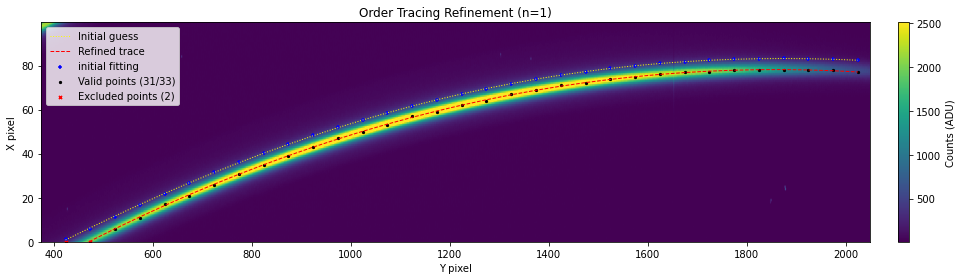

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



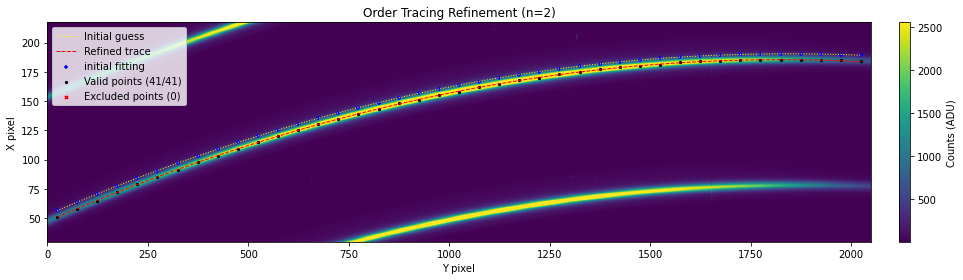

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



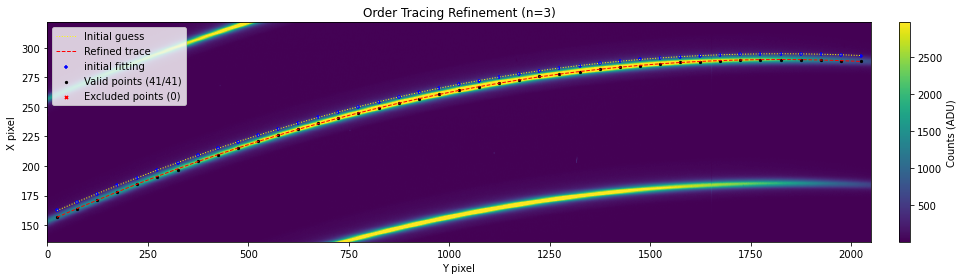

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



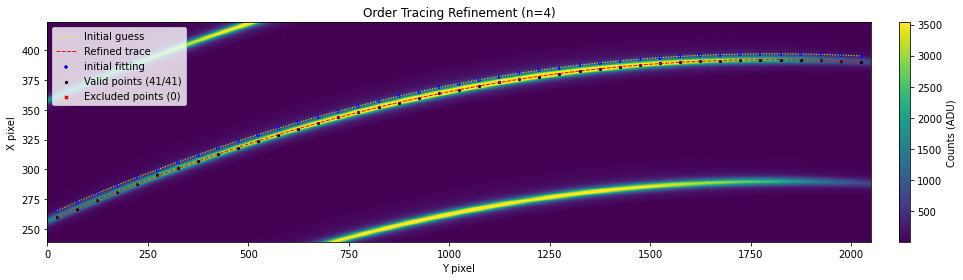

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



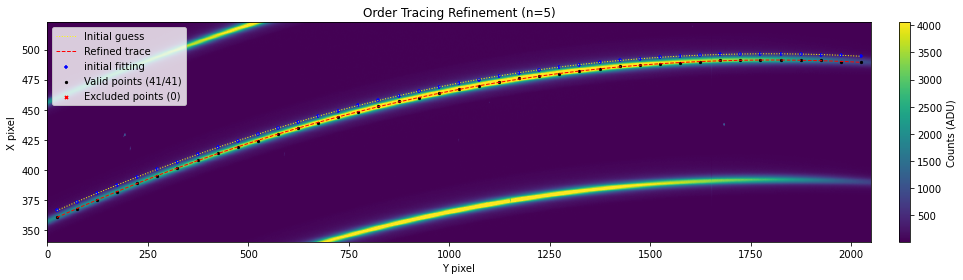

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



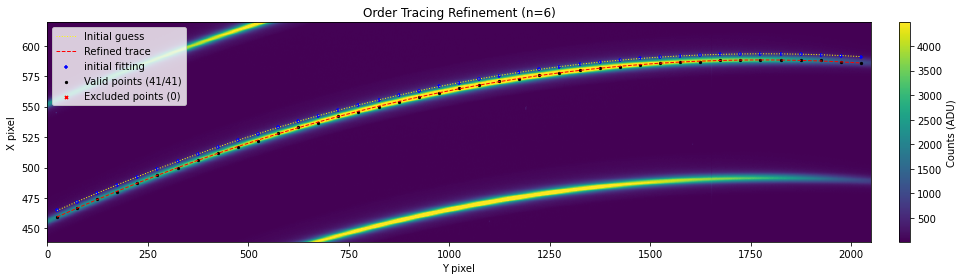

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



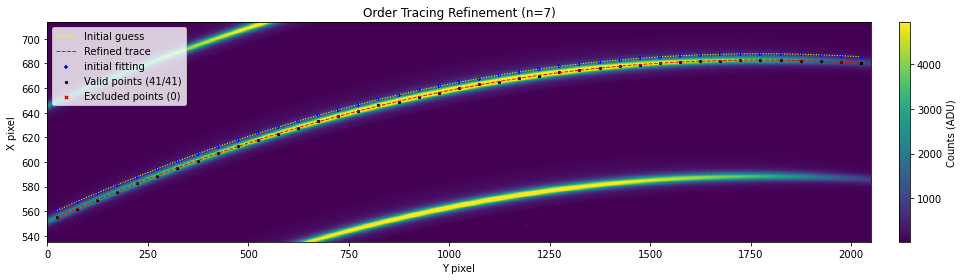

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



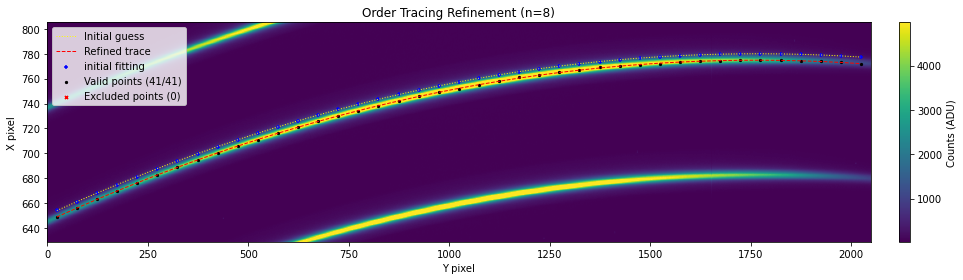

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



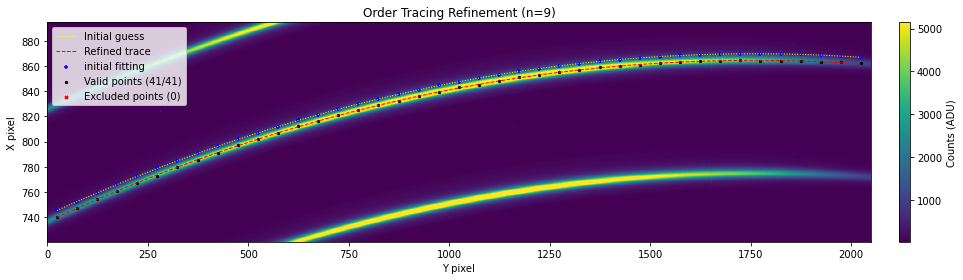

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



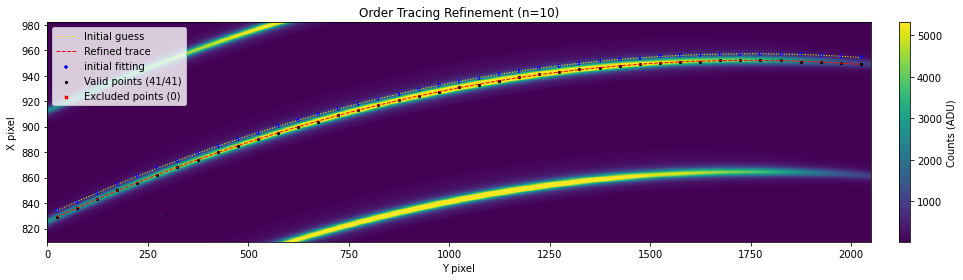

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



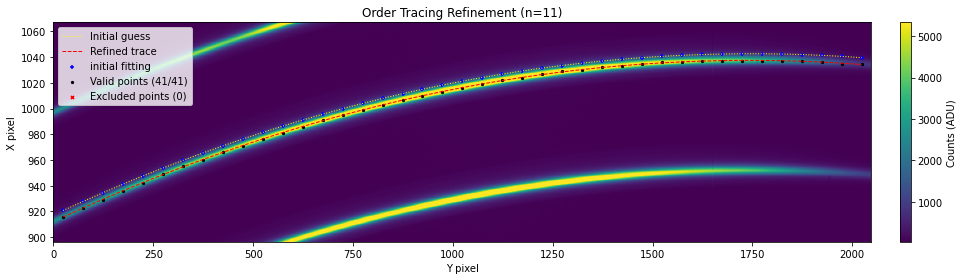

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



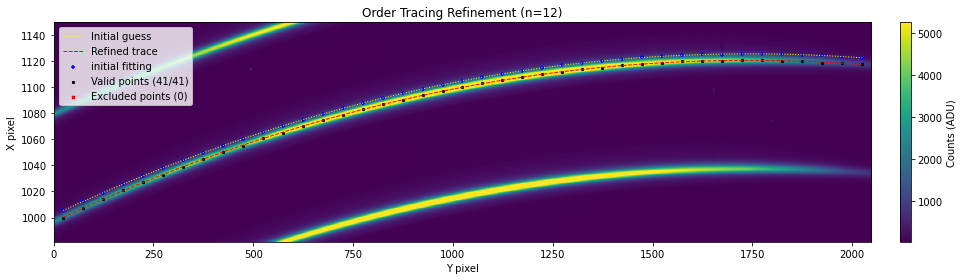

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



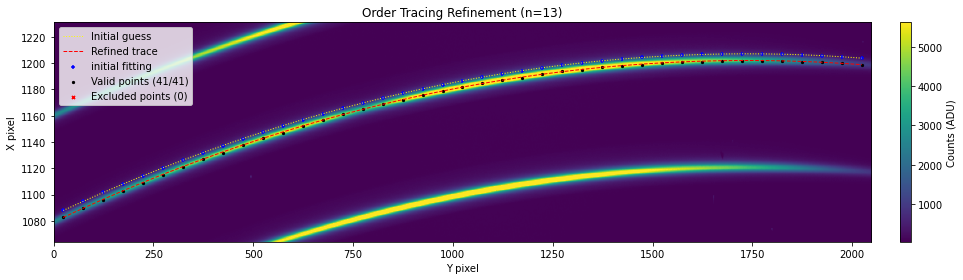

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



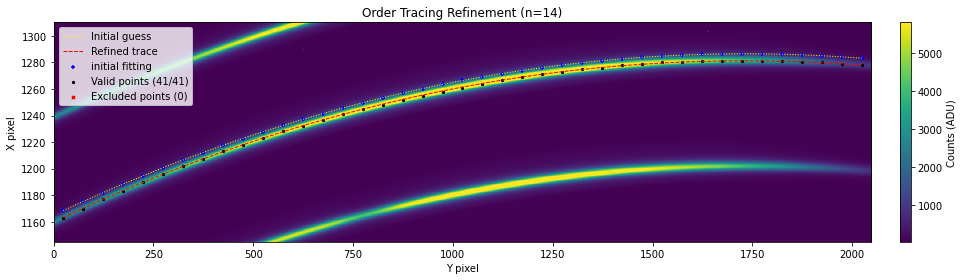

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



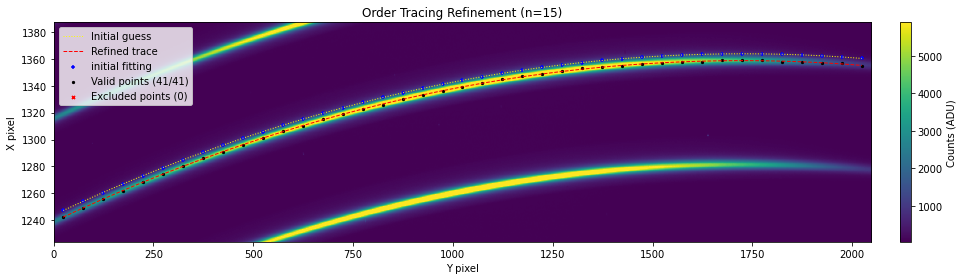

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



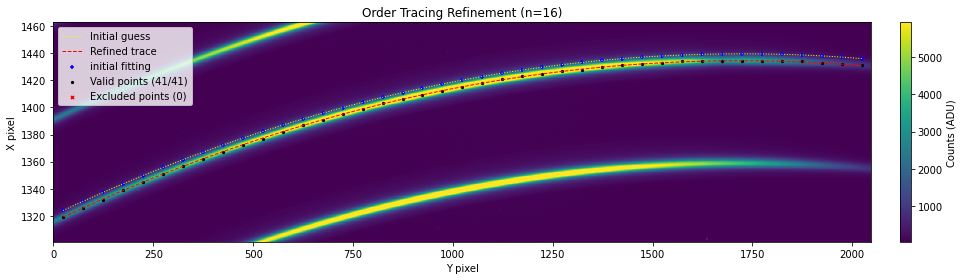

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



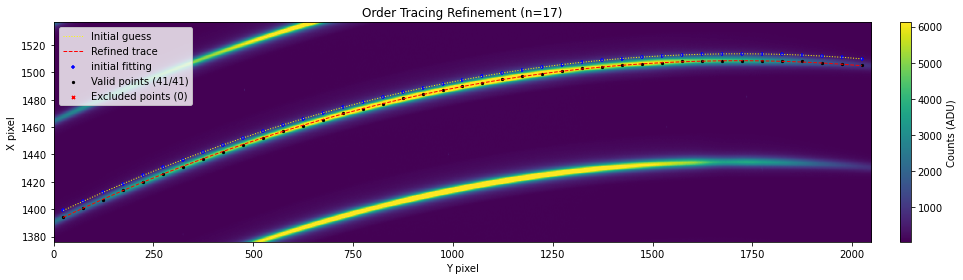

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



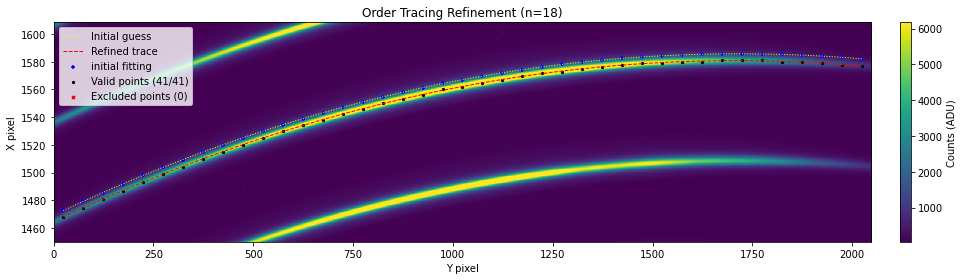

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



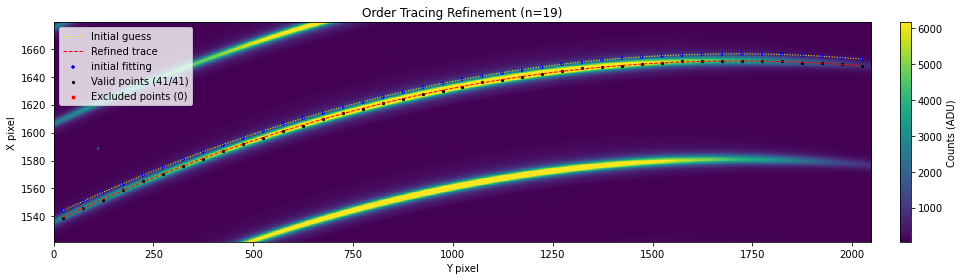

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



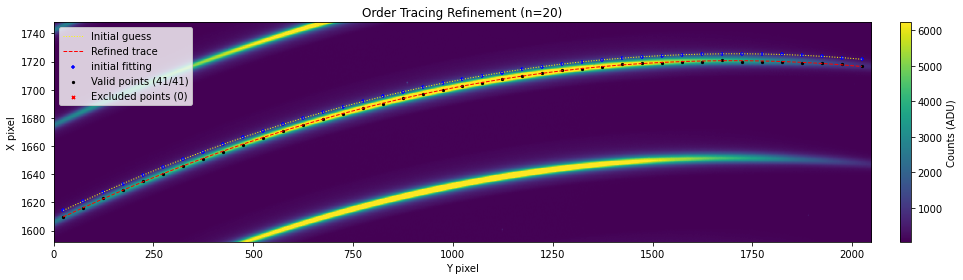

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



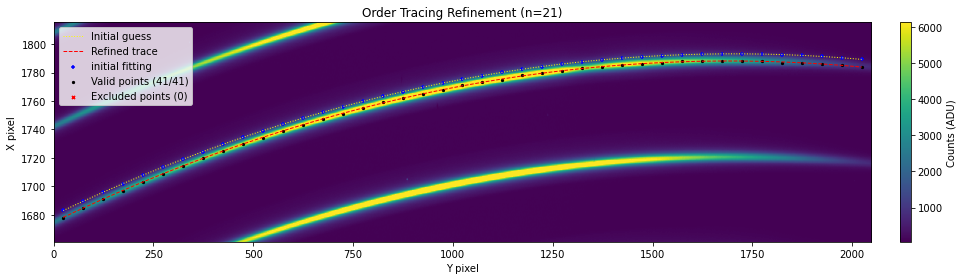

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



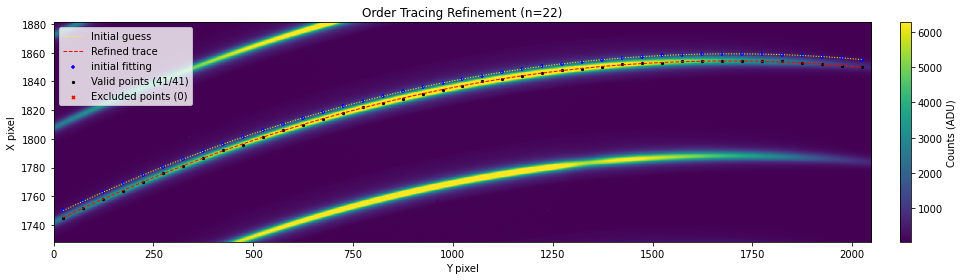

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



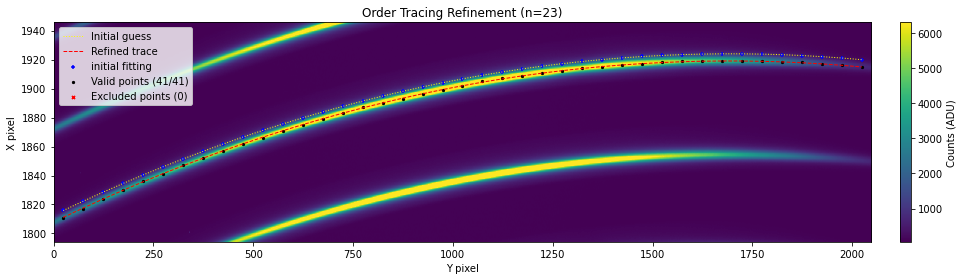

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



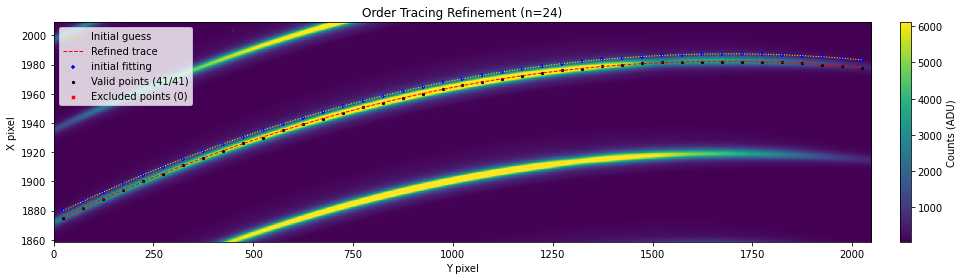

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



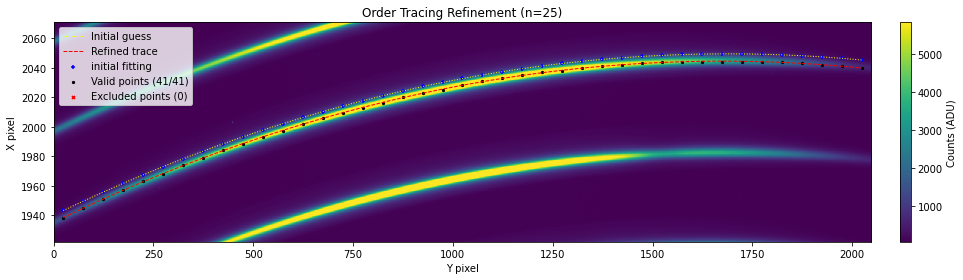

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



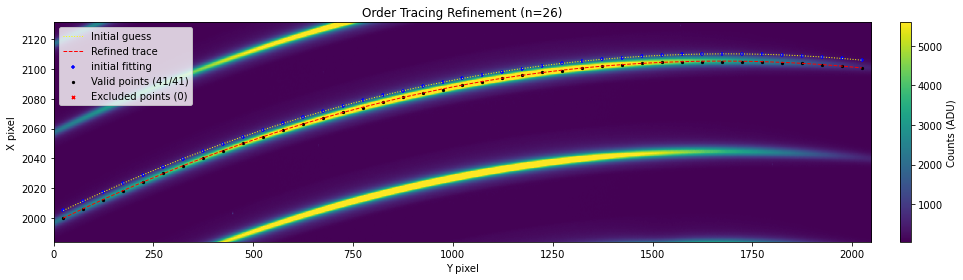

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



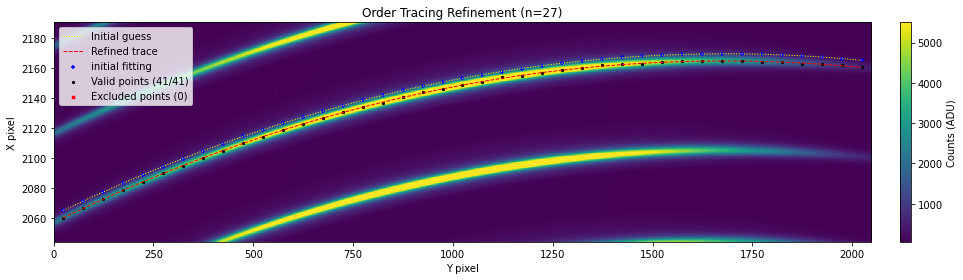

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



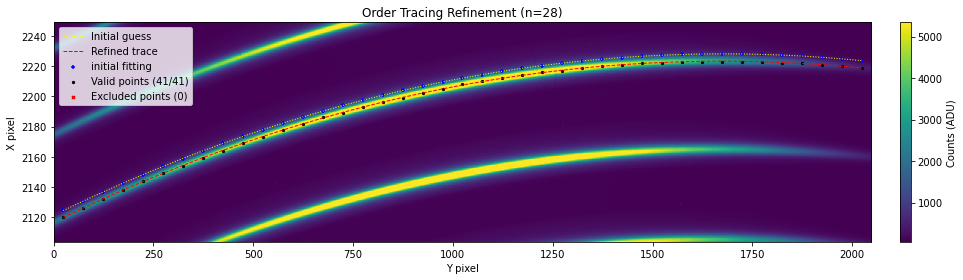

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



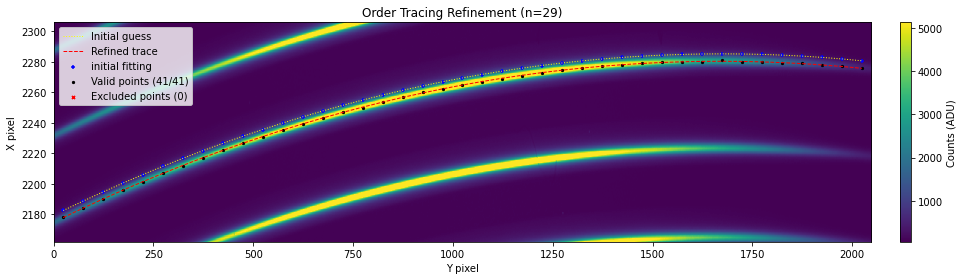

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



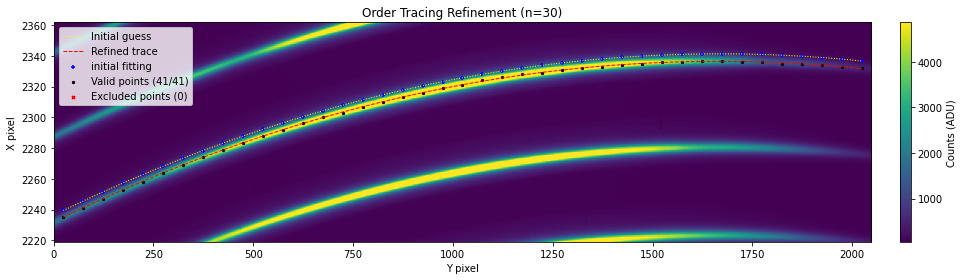

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



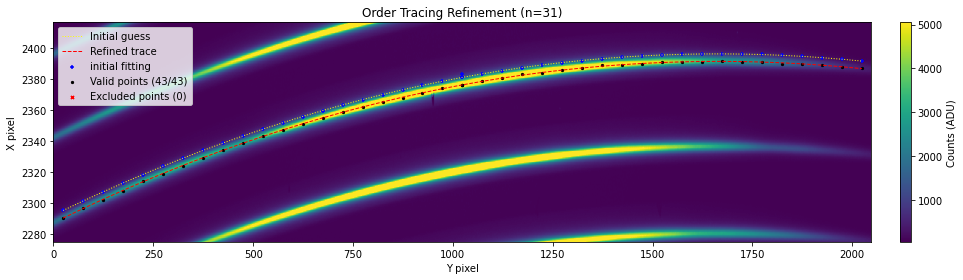

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



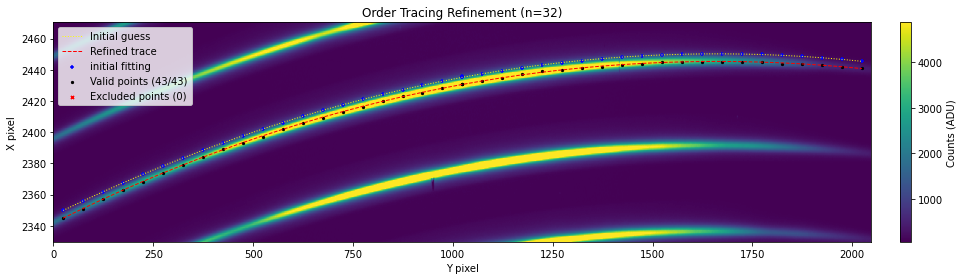

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



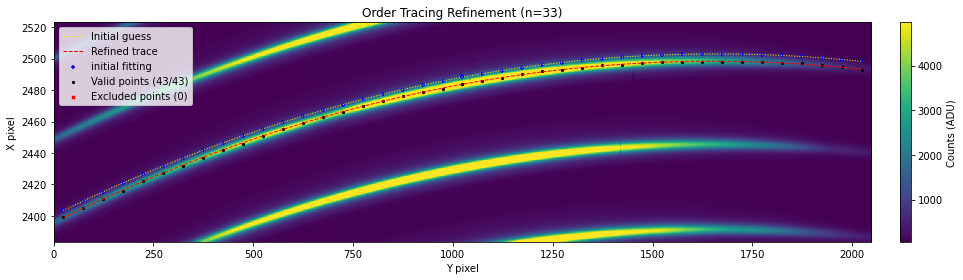

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



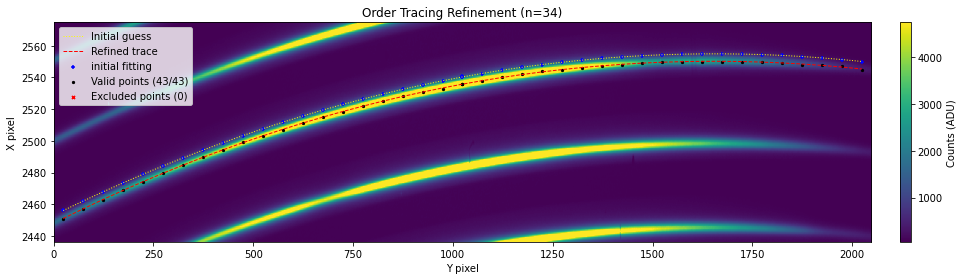

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



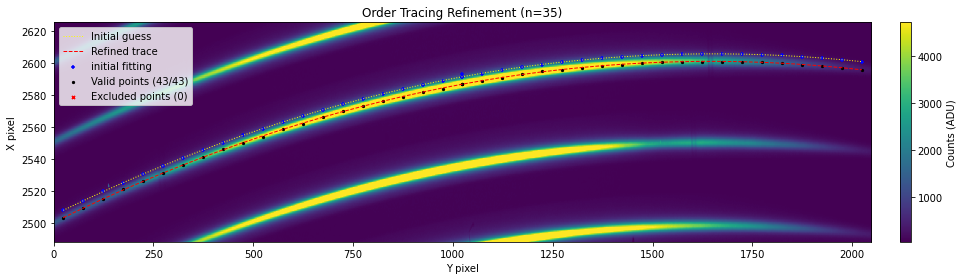

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



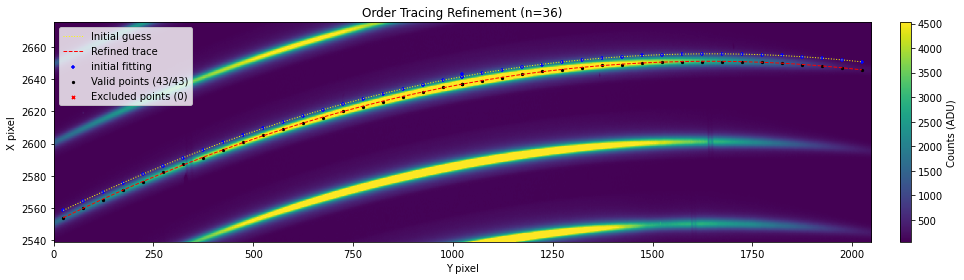

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



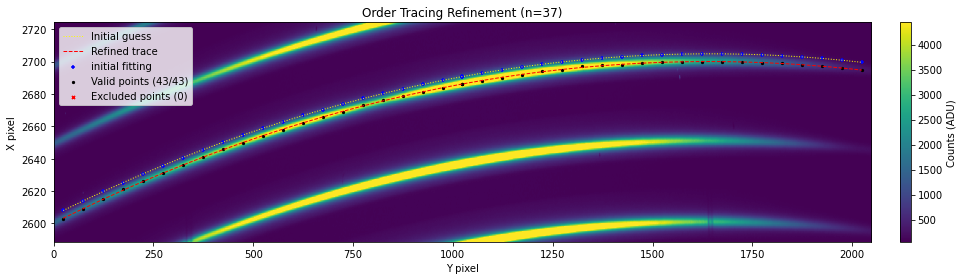

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



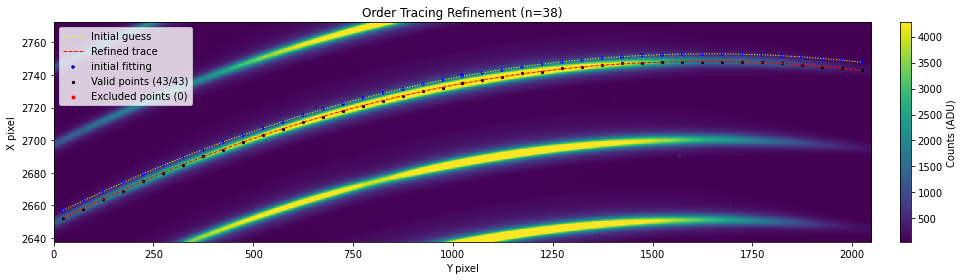

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



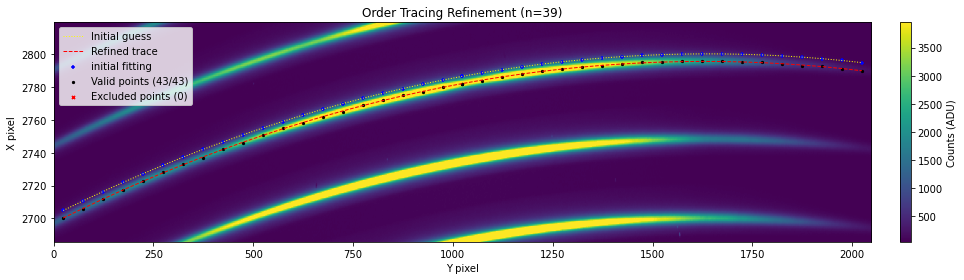

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



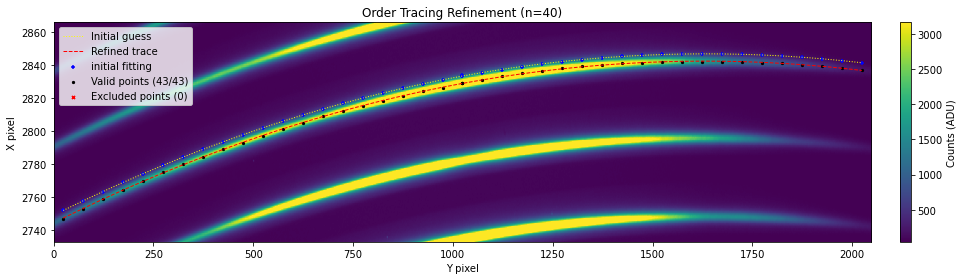

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



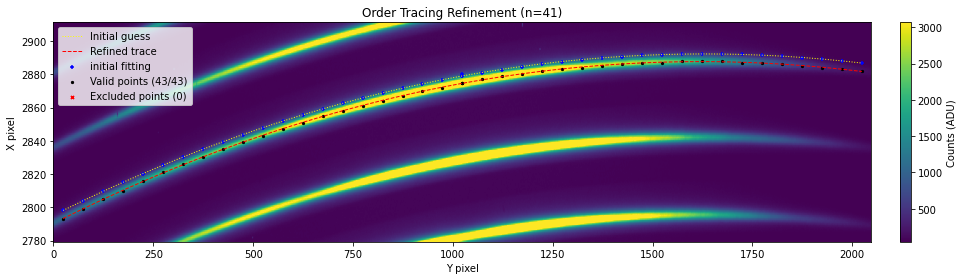

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



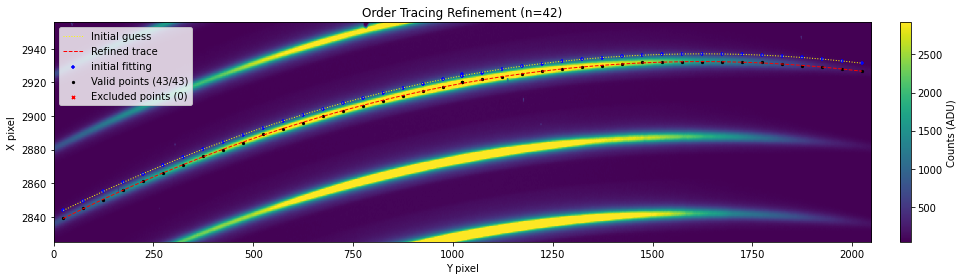

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



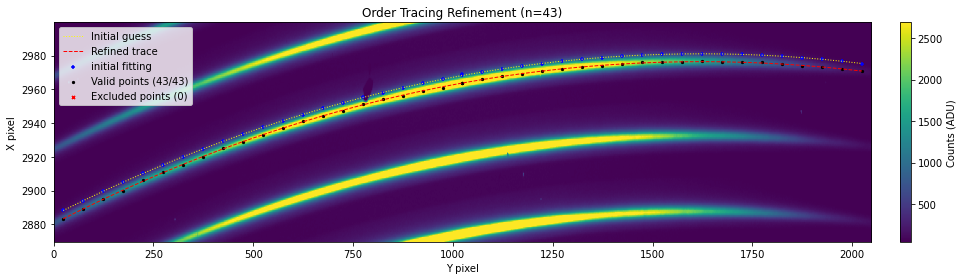

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



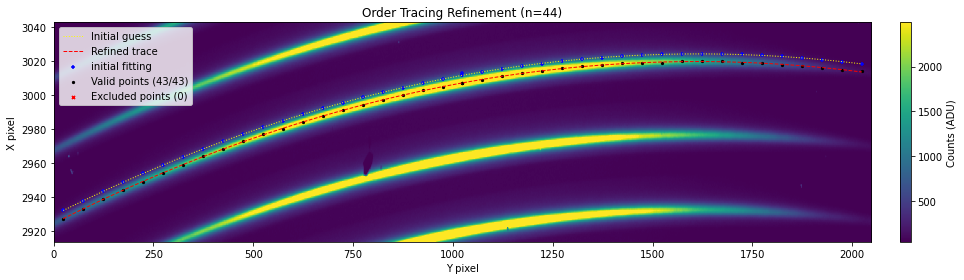

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



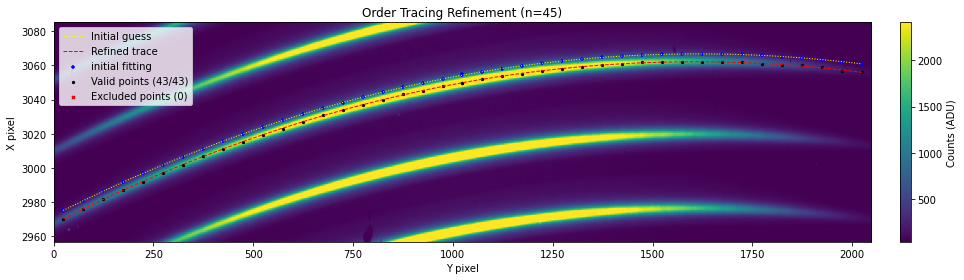

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



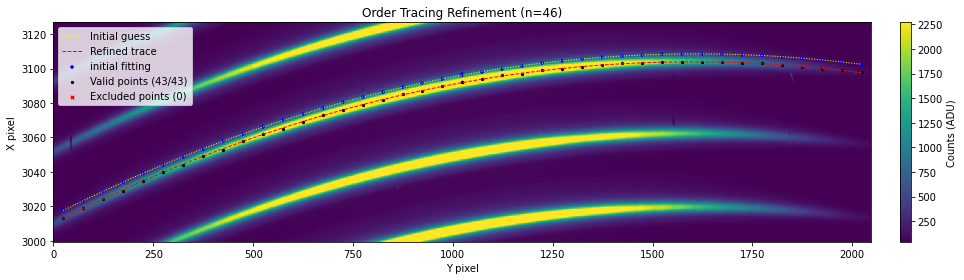

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



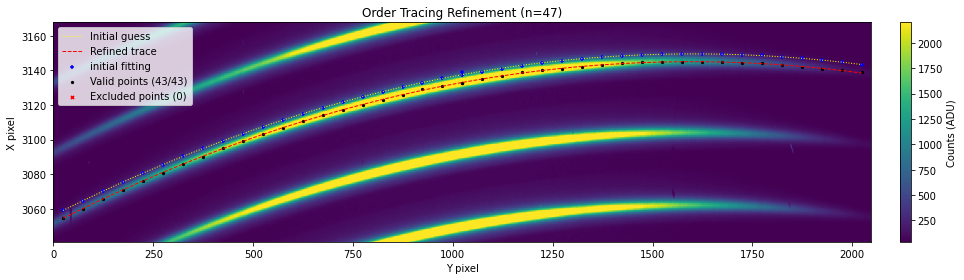

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



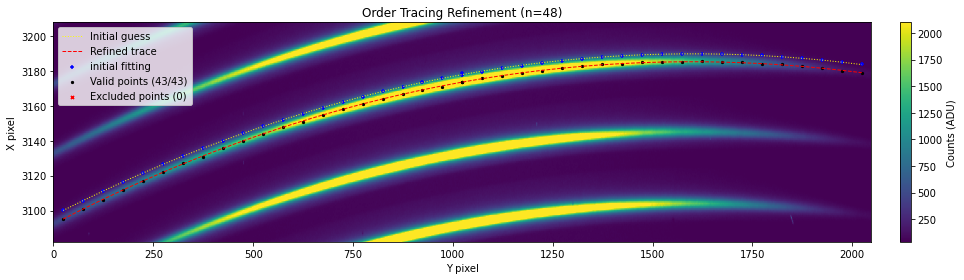

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



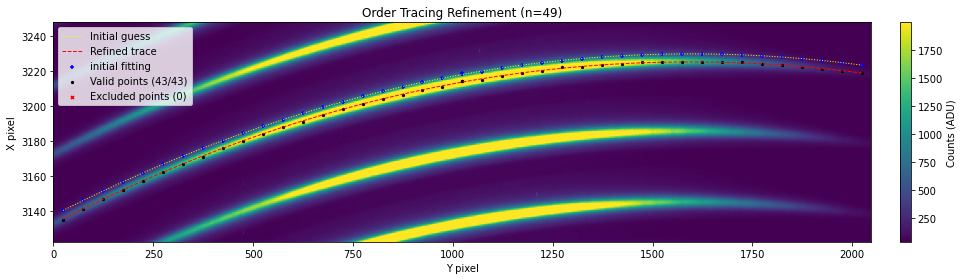

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



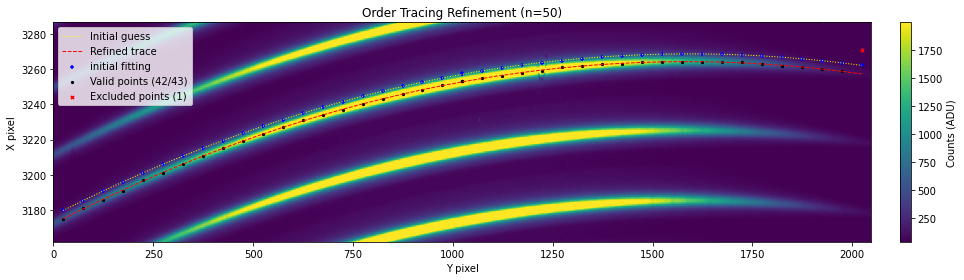

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



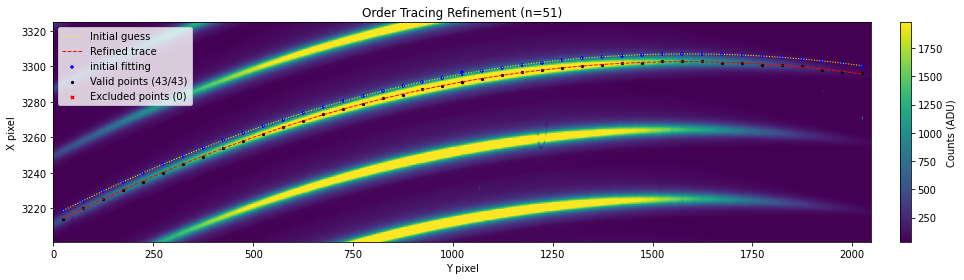

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



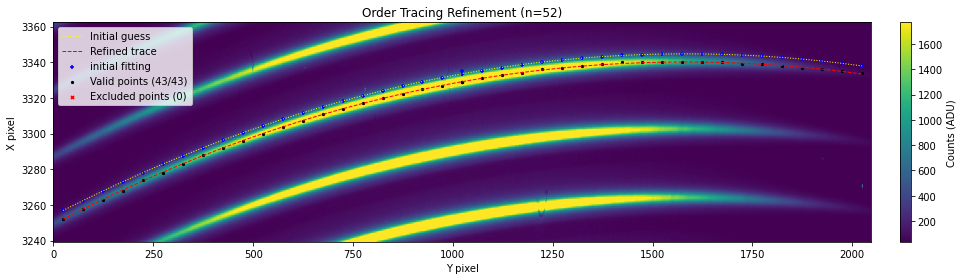

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



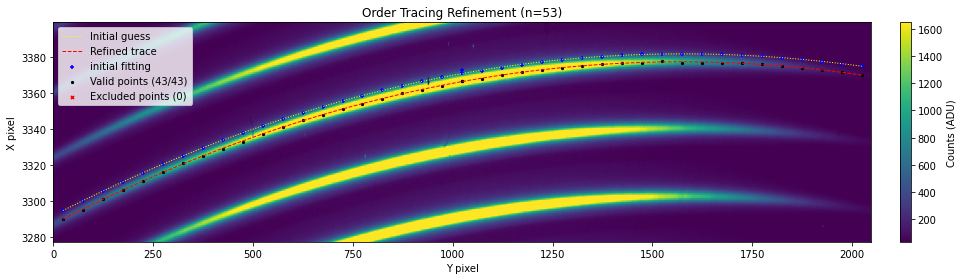

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



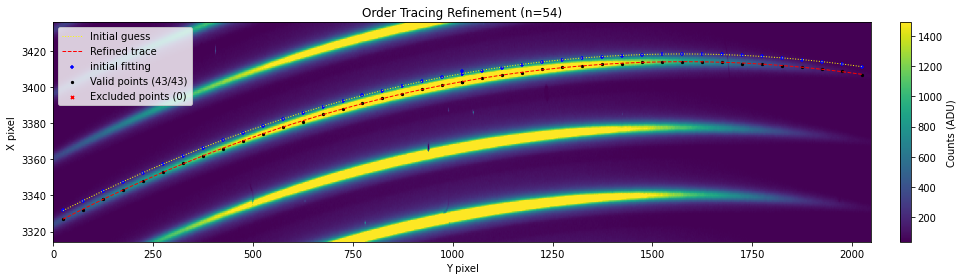

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



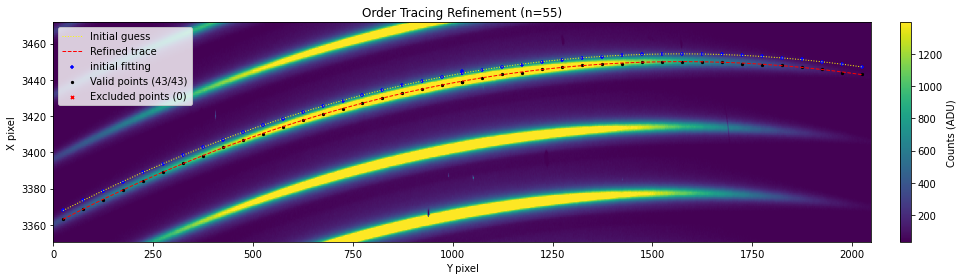

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



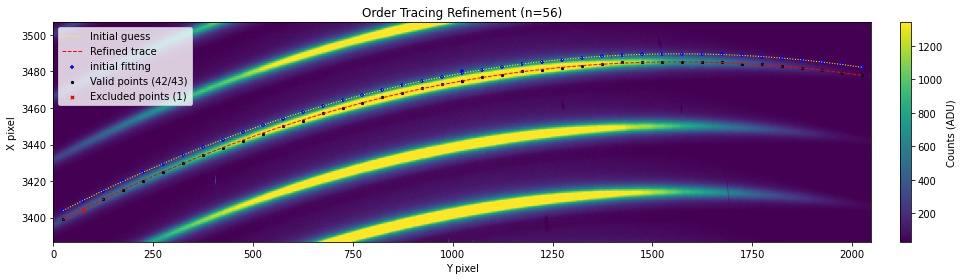

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



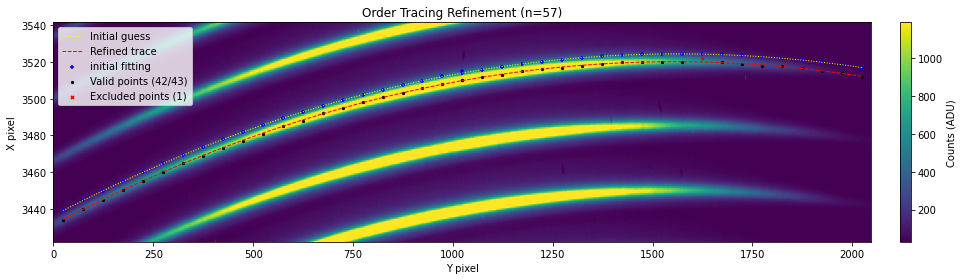

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



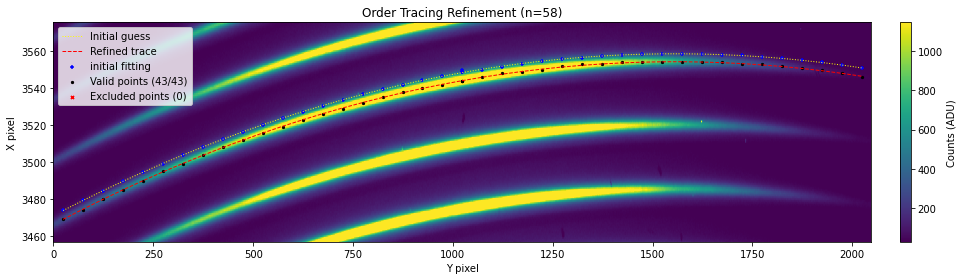

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



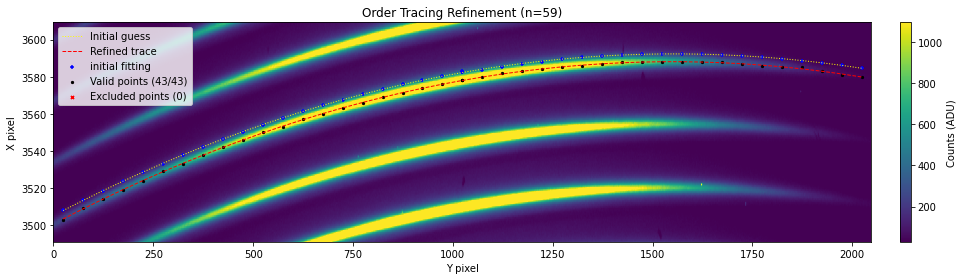

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



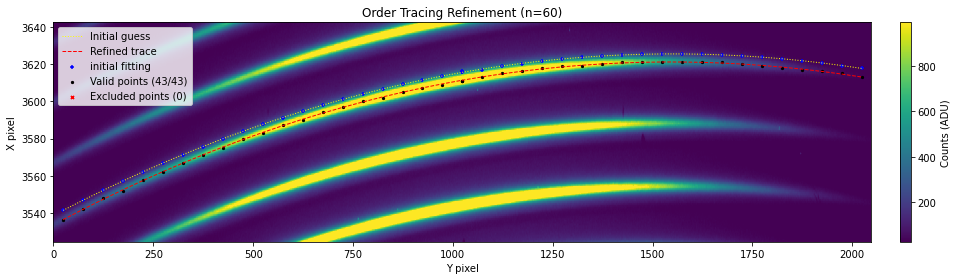

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



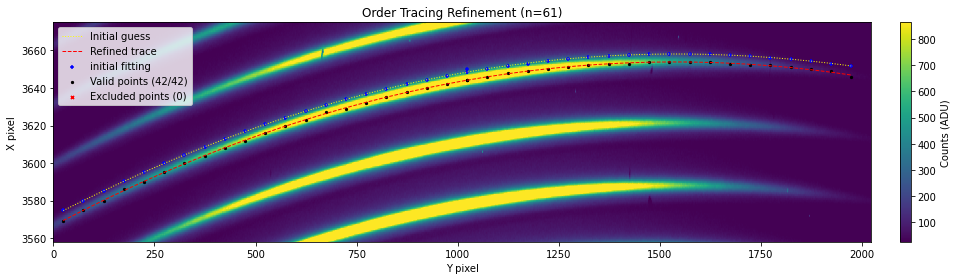

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



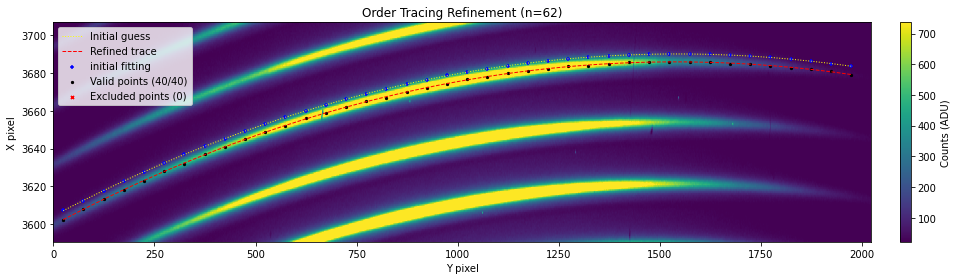

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



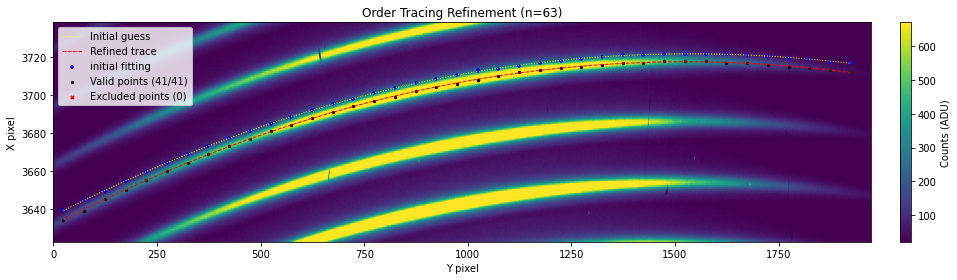

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



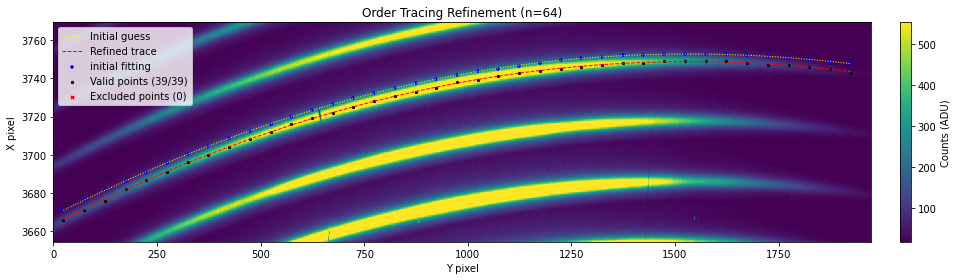

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



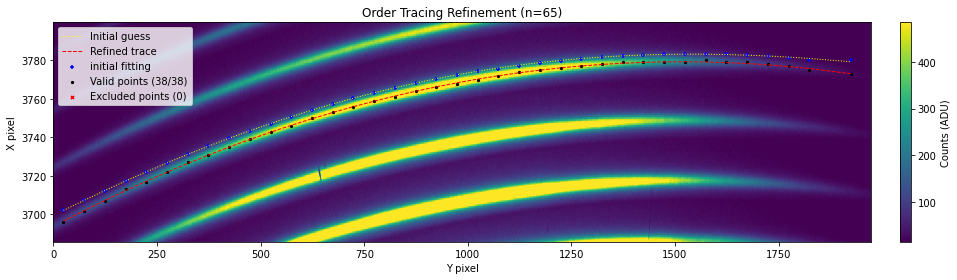

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



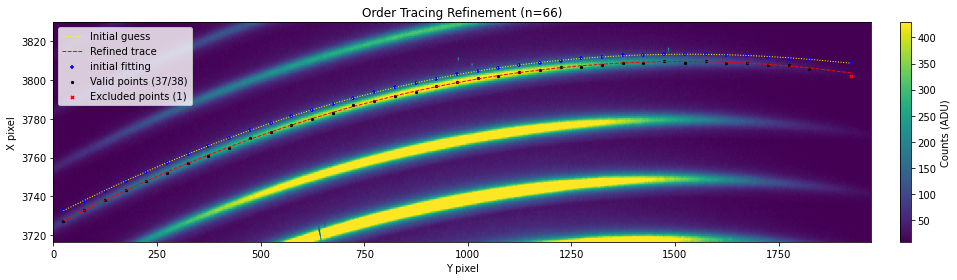

[INFO] Saving trace coefficients
[INFO] Trace Orders completed in 345.55s
[INFO] Generating tracing QC plot
[INFO] Tracing QC plot saved: D:/SOAR/Steles/2026-01-29_blue/RED/plots\master_HR1996_600mas_tracing.png
[INFO] Generating aperture QC plots
[INFO] Aperture QC plot saved: D:/SOAR/Steles/2026-01-29_blue/RED/plots\master_flat_aperture.png
[INFO] Aperture QC plot saved: D:/SOAR/Steles/2026-01-29_blue/RED/plots\master_ThAr_600mas_aperture.png
[INFO] Aperture QC plot saved: D:/SOAR/Steles/2026-01-29_blue/RED/plots\master_HR1996_600mas_aperture.png
[INFO] Extracting and linearizing orders
[INFO] [1/66] Extracting order
[INFO] [2/66] Extracting order
[INFO] [3/66] Extracting order
[INFO] [4/66] Extracting order
[INFO] [5/66] Extracting order
[INFO] [6/66] Extracting order
[INFO] [7/66] Extracting order
[INFO] [8/66] Extracting order
[INFO] [9/66] Extracting order
[INFO] [10/66] Extracting order
[INFO] [11/66] Extracting order
[INFO] [12/66] Extracting order
[INFO] [13/66] Extracting ord

In [5]:
pipeline_partI_blue = STELES_Pipeline(config_blue)
pipeline_partI_blue.run()

#pipeline_partI_red = STELES_Pipeline(config_red)
#pipeline_partI_red.run()

[INFO] Identifying channel
[INFO] Retrieving parameters for the red channel
[INFO] 
[INFO] ==== STELES PIPELINE CONFIG ====
[INFO] channel: red
[INFO] n_orders: 48
[INFO] gain_per_amplifier: [1.035, 1.0]
[INFO] gain: 2.36
[INFO] rdnoise: 8.47
[INFO] transpose: False
[INFO] y_range: [500, 3250]
[INFO] x_guesses: [72, 155, 235, 311, 384, 454, 521, 586, 648, 708, 765, 820, 873, 925, 975, 1023, 1069, 1115, 1158, 1200, 1241, 1280, 1319, 1356, 1392, 1427, 1460, 1494, 1526, 1558, 1588, 1617, 1647, 1675, 1702, 1728, 1754, 1779, 1804, 1828, 1851, 1874, 1895, 1917, 1938, 1958, 1978, 1997]
[INFO] wavelength_file: ./db/red_wavelength_solution_2026-01.xlsx
[INFO] dry_run: False
[INFO] run_stages: ['all']
[INFO] saturation_threshold: 40000
[INFO] raw_directory: D:/SOAR/Steles/2026-01-29_red/
[INFO] save_plots: True
[INFO] show_plots: False
[INFO] flat_list: ['flat_isb_3000mas_0034', 'flat_isb_3000mas_0035', 'flat_isb_3000mas_0036']
[INFO] sci_list: ['sci_0053']
[INFO] arc_list: ['thar_600mas_0013', 

INFO: Iteration 1: Found 1394 cosmic-ray pixels, Total: 1394 [lacosmic.lacosmic]


[INFO] Iteration 2: Found 450 cosmic-ray pixels, Total: 1844


INFO: Iteration 2: Found 450 cosmic-ray pixels, Total: 1844 [lacosmic.lacosmic]


[INFO] Iteration 3: Found 214 cosmic-ray pixels, Total: 2058


INFO: Iteration 3: Found 214 cosmic-ray pixels, Total: 2058 [lacosmic.lacosmic]


... (3 outputs left out)

INFO: splitting each image into 4 chunks to limit memory usage to 350000000.0 bytes. [ccdproc.combiner]


[INFO] splitting each image into 2 chunks to limit memory usage to 350000000.0 bytes.


INFO: splitting each image into 2 chunks to limit memory usage to 350000000.0 bytes. [ccdproc.combiner]


[INFO] Create Master Frames completed in 9.67s
[INFO] Loading master frames
[INFO] Generating QC plots for master frames
[INFO] QC plot saved: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_dataset.png
[INFO] Tracing spectral orders
 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



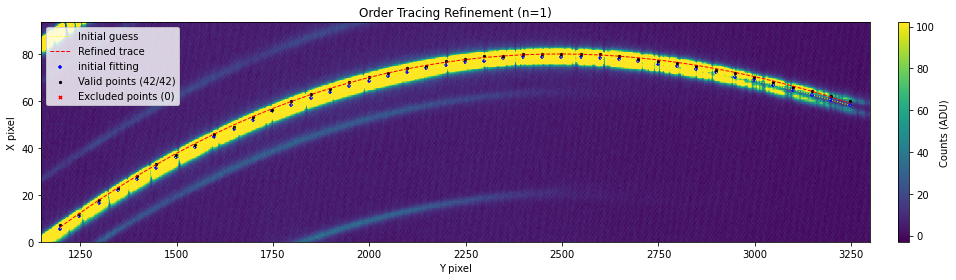

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



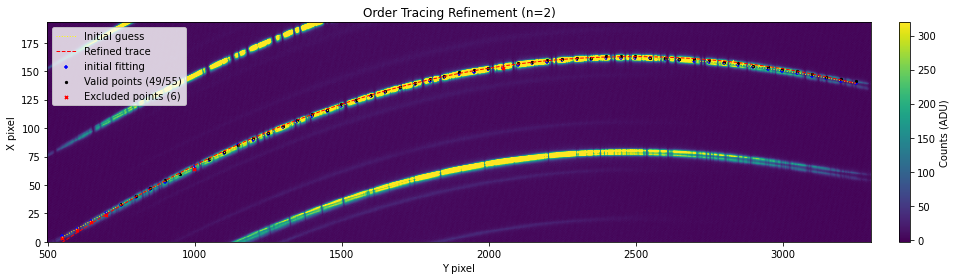

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



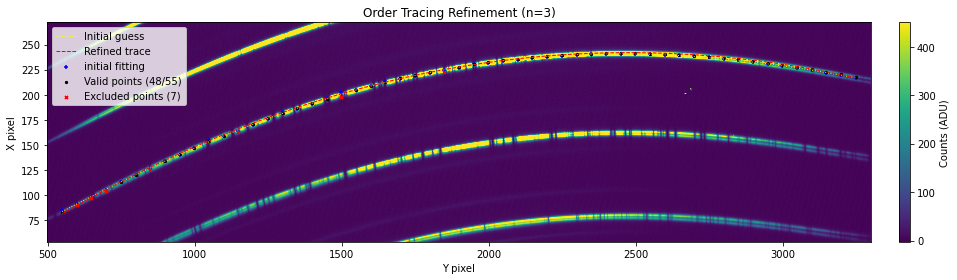

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



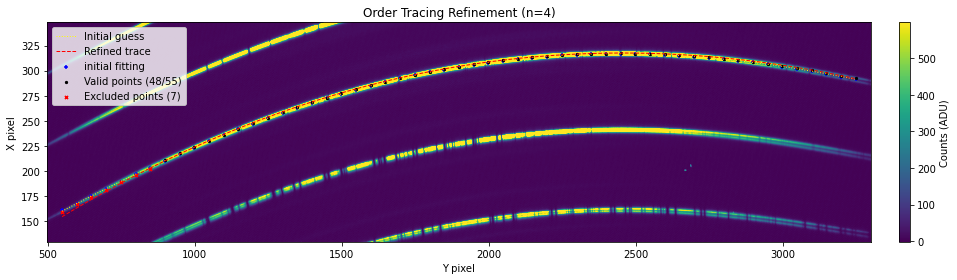

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



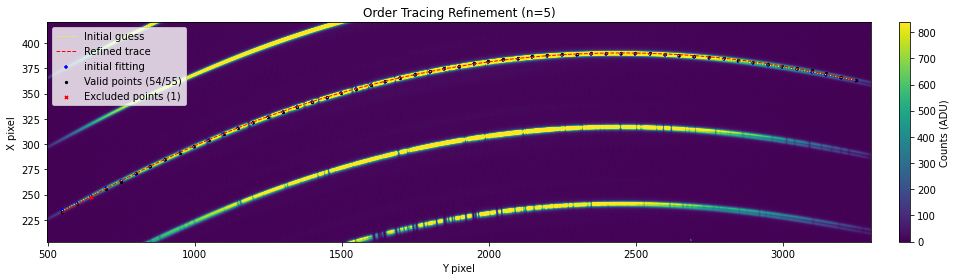

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



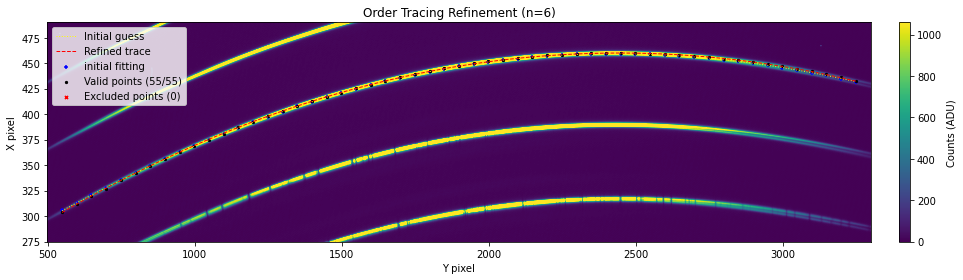

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



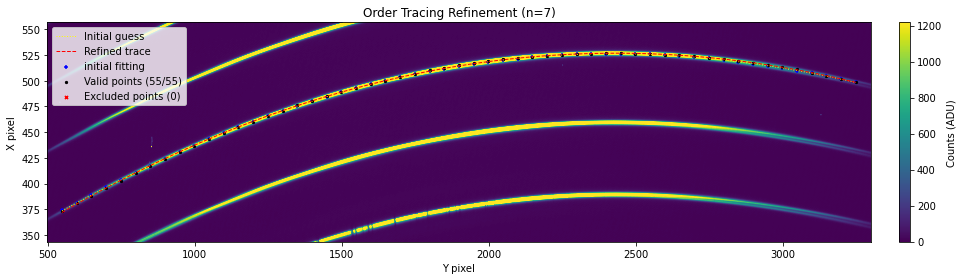

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



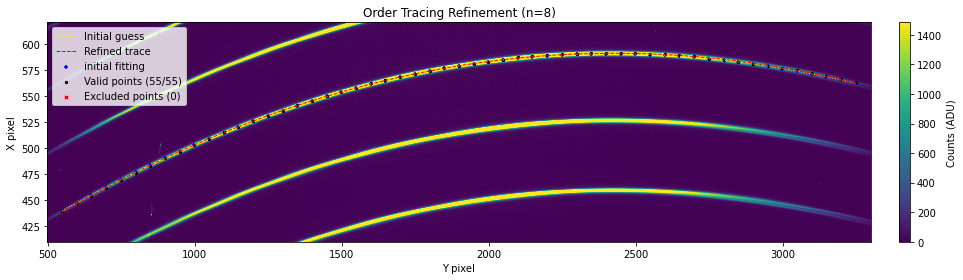

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



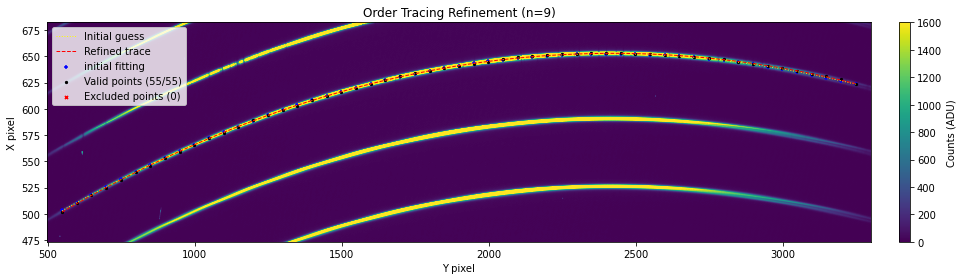

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



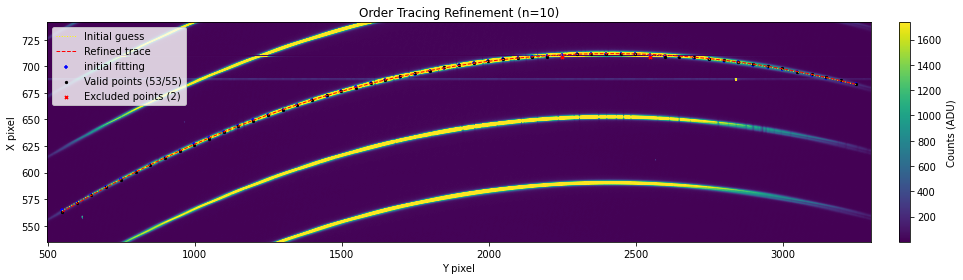

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



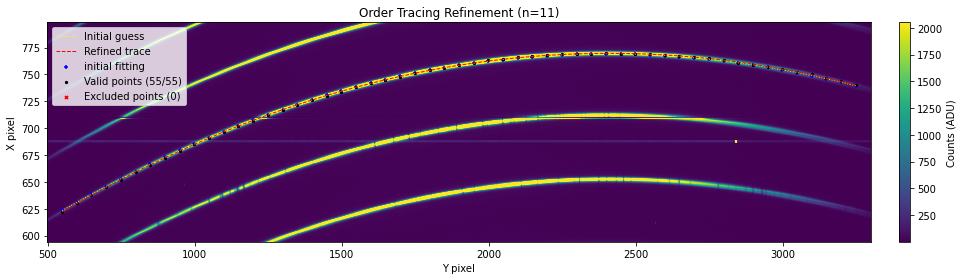

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



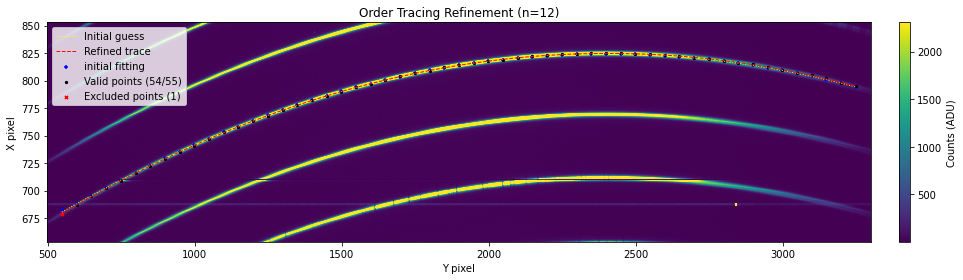

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



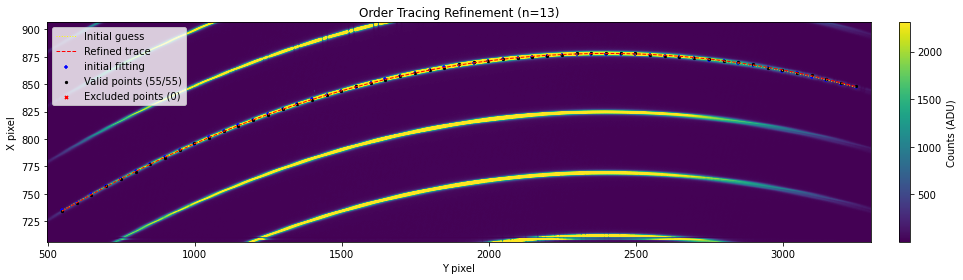

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



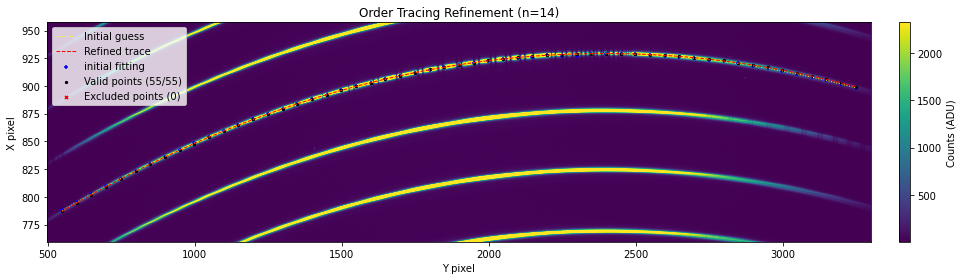

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



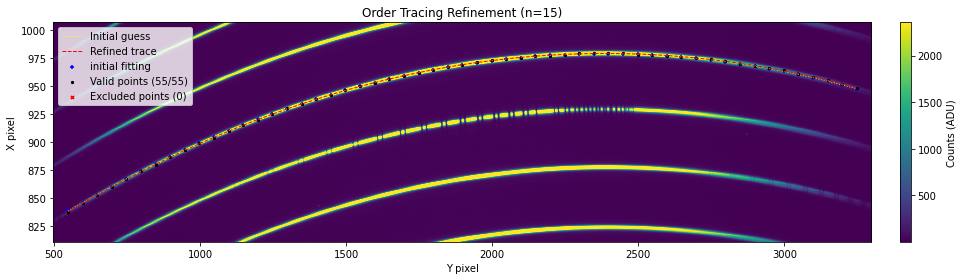

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



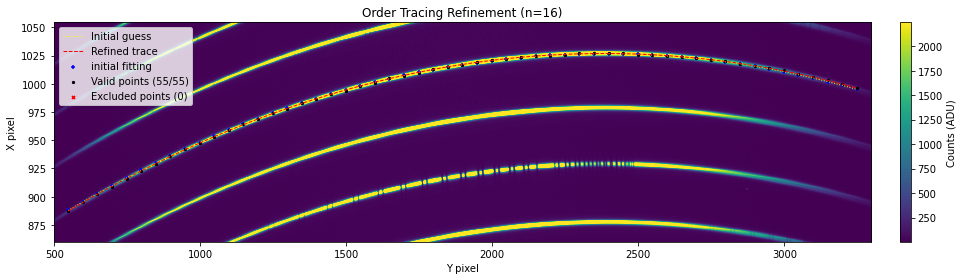

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



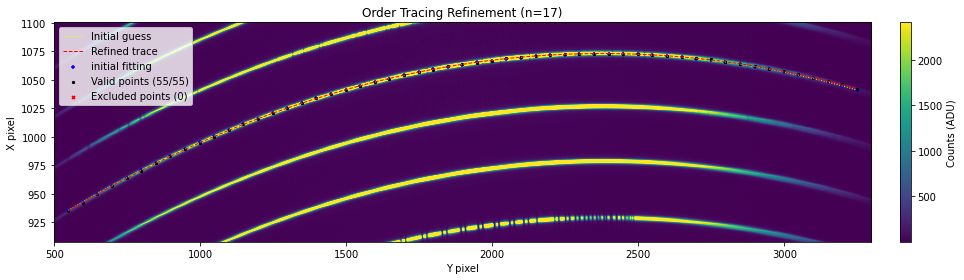

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



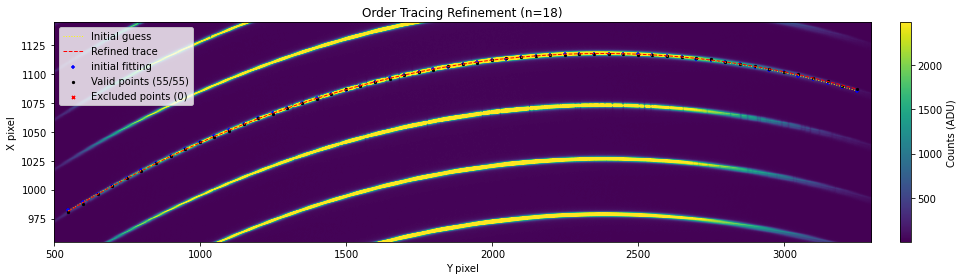

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



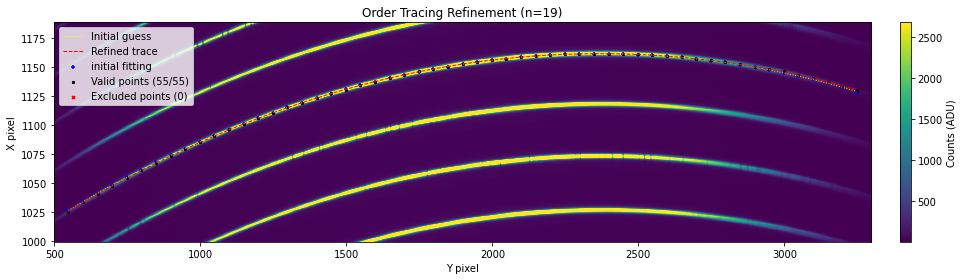

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



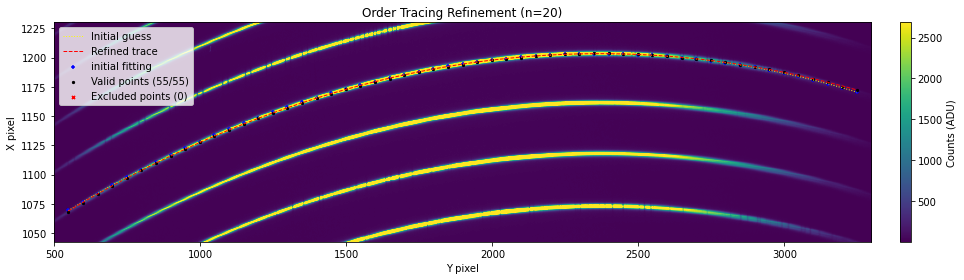

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



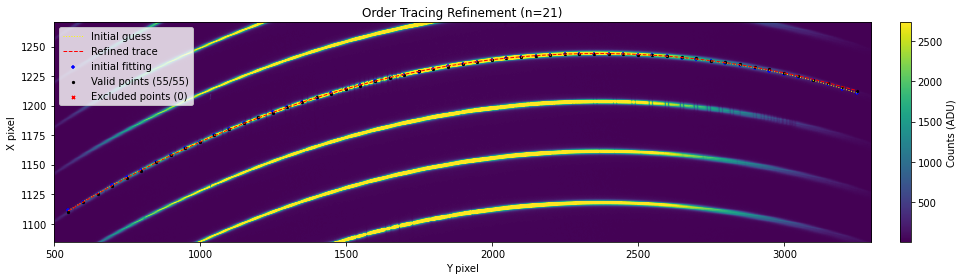

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



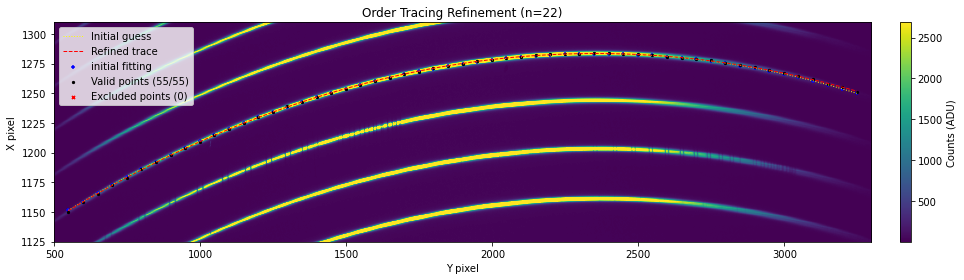

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



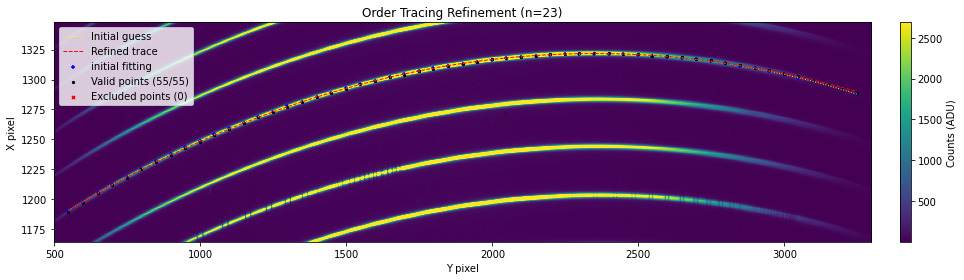

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



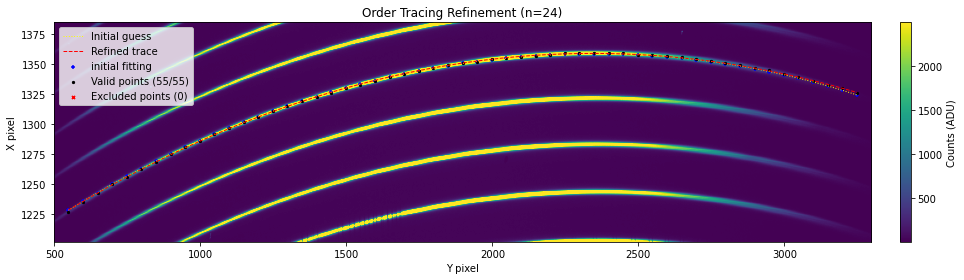

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



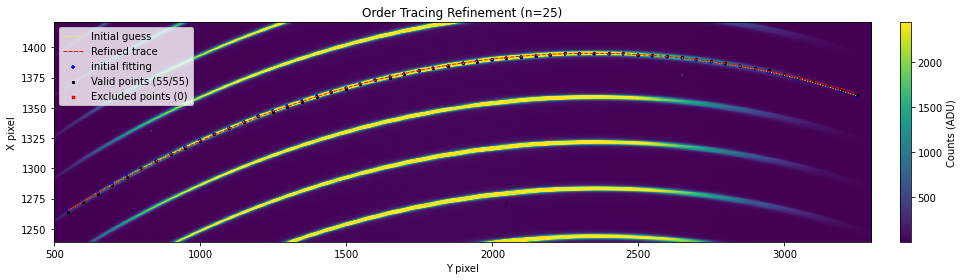

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



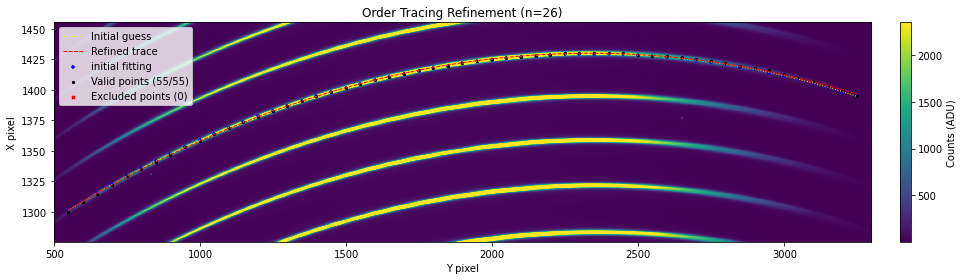

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



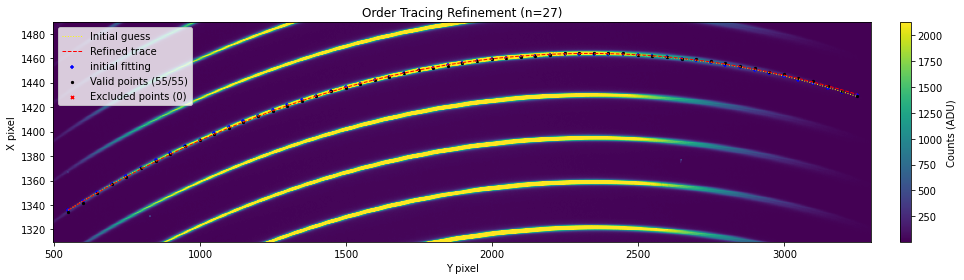

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



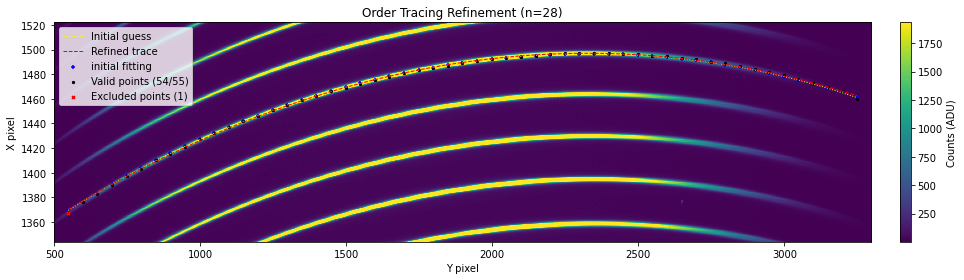

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



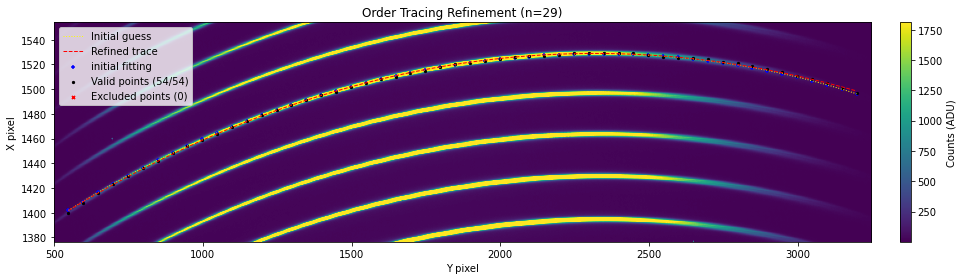

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



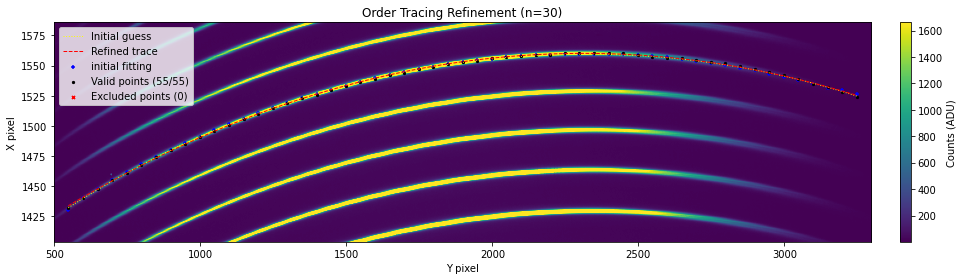

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



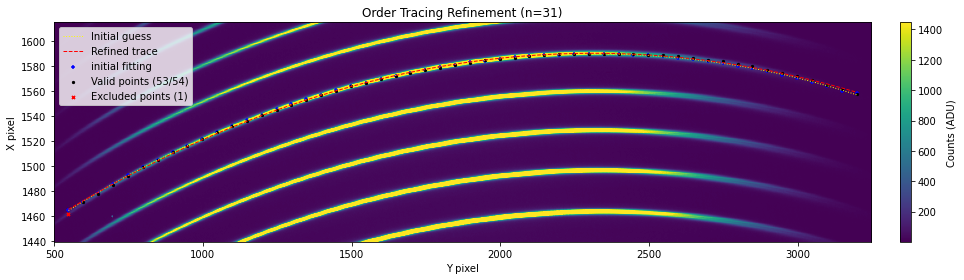

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



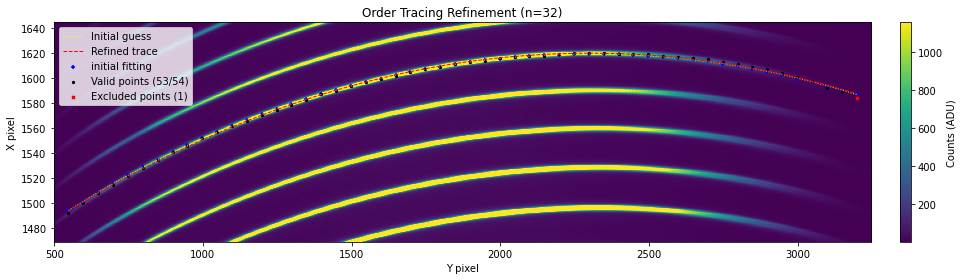

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



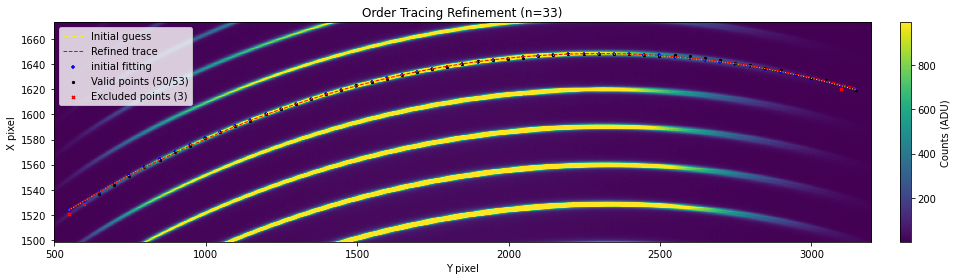

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



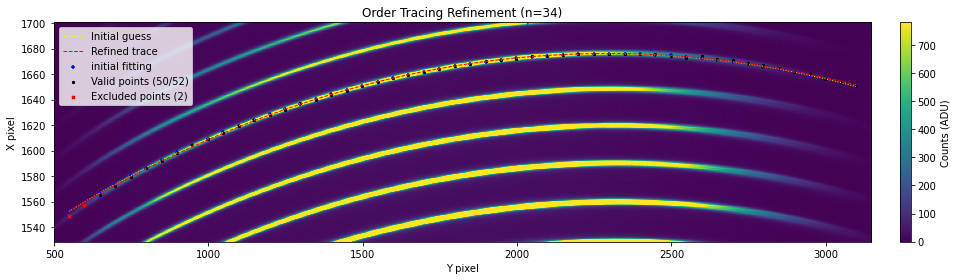

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



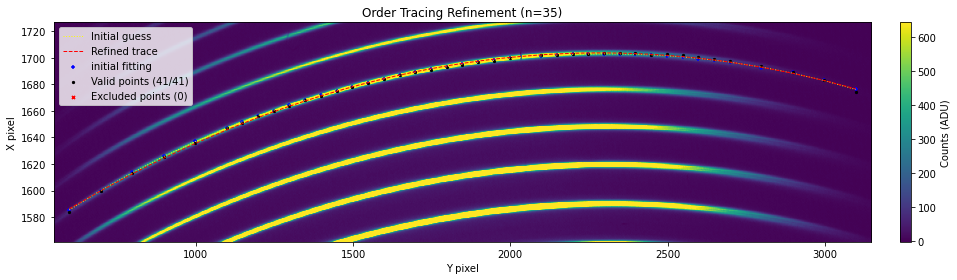

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



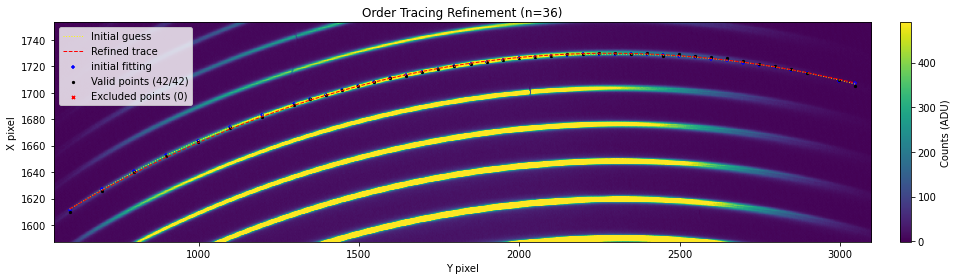

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



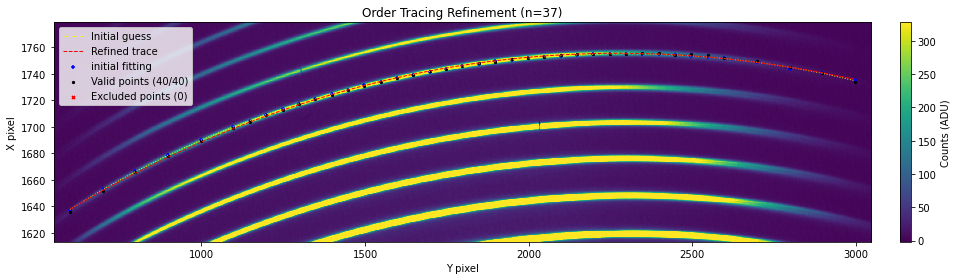

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



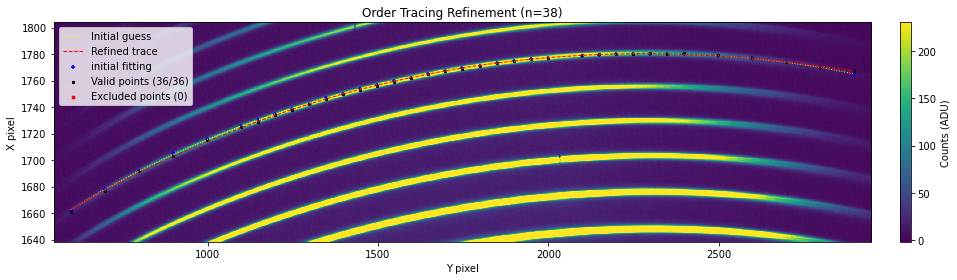

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



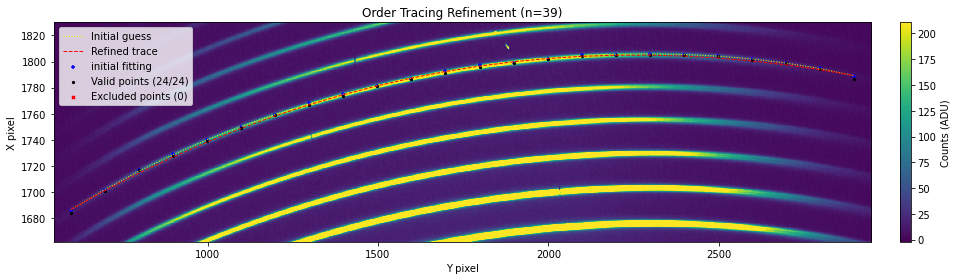

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



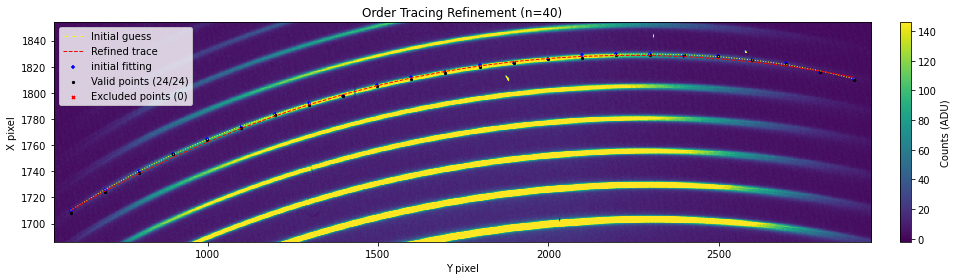

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



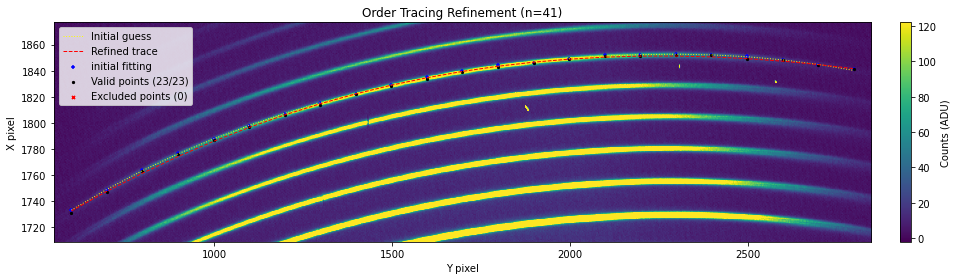

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



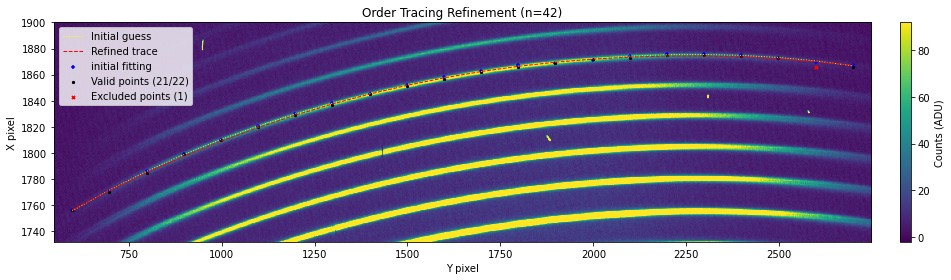

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



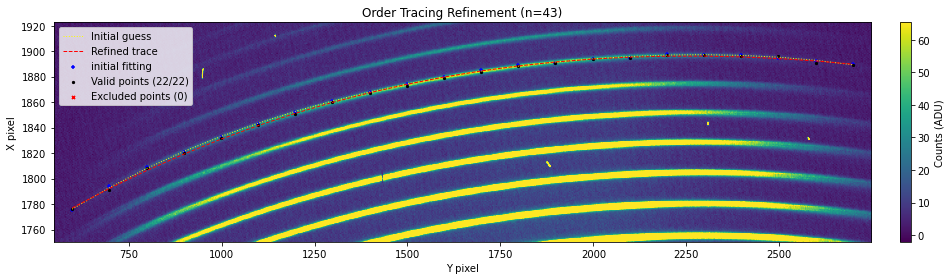

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



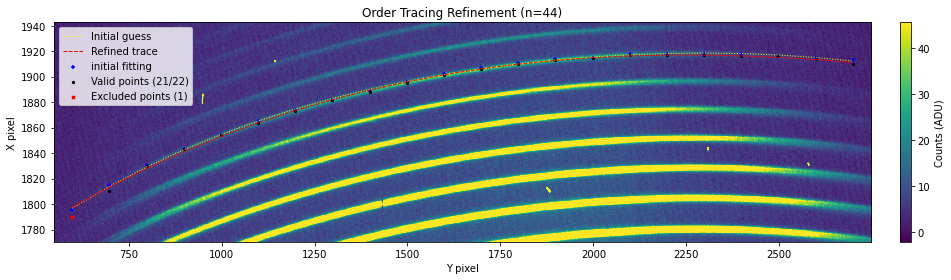

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



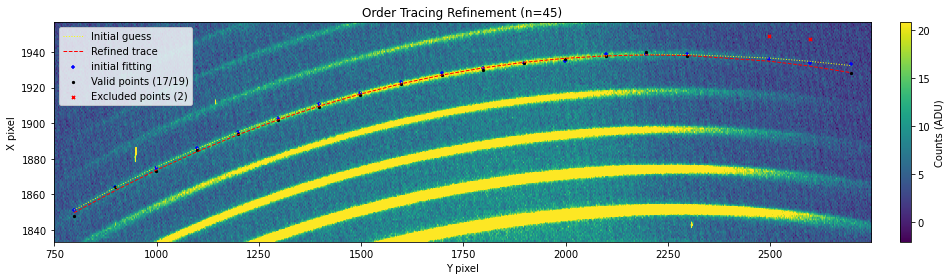

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



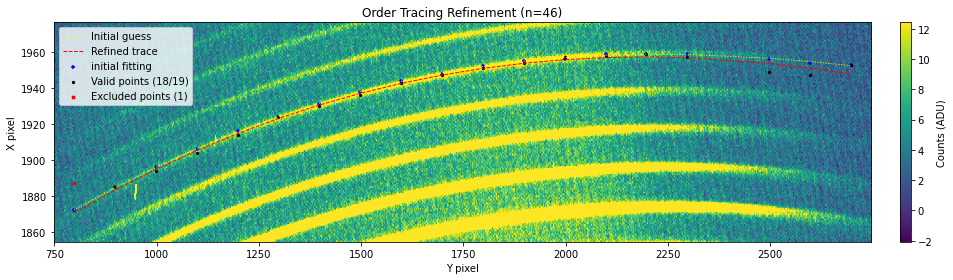

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



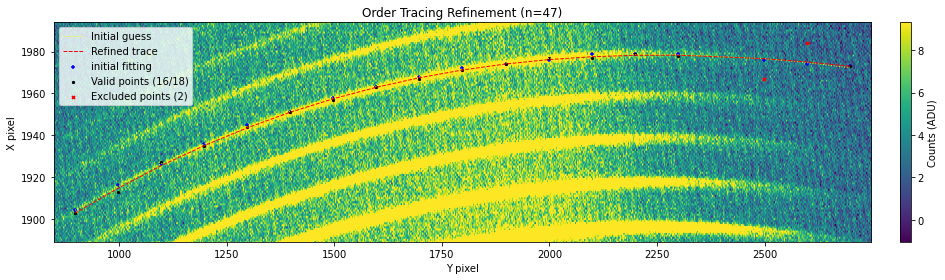

 [astropy.modeling.fitting]
[WARNING] The fit may be poorly conditioned



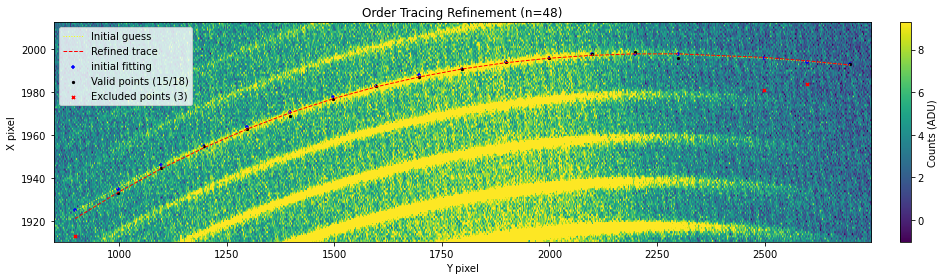

[INFO] Saving trace coefficients
[INFO] Trace Orders completed in 157.37s
[INFO] Generating tracing QC plot
[WARNING] Trace intersection: orders 44 and 45 at (x=1890.32, y=3294.77)
[INFO] Tracing QC plot saved: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_tracing.png
[INFO] Generating aperture QC plots
[INFO] Aperture QC plot saved: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_flat_aperture.png
[INFO] Aperture QC plot saved: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_ThAr_600mas_aperture.png
[INFO] Aperture QC plot saved: D:/SOAR/Steles/2026-01-29_red/RED/plots\master_HR1996_600mas_aperture.png
[INFO] Extracting and linearizing orders
[INFO] [1/48] Extracting order
[INFO] [2/48] Extracting order
[INFO] [3/48] Extracting order
[INFO] [4/48] Extracting order
[INFO] [5/48] Extracting order
[INFO] [6/48] Extracting order
[INFO] [7/48] Extracting order
[INFO] [8/48] Extracting order
[INFO] [9/48] Extracting order
[INFO] [10/48] Extracting order
[INFO] [11/48] Extractin

In [4]:
#pipeline_debug = STELES_Pipeline(config_blue)
pipeline_debug = STELES_Pipeline(config_red)
pipeline_debug.run()
#pipeline_debug.merge_extensions()
#pipeline_debug.cosmic_ray_clean()
#pipeline_debug.scale_arcs()
#pipeline_debug.create_master_frames()
#pipeline_debug.load_master_frames()
#pipeline_debug.quality_control_master_frames()
#pipeline_debug.trace_orders()
#pipeline_debug.load_trace()
#pipeline_debug.quality_control_tracing()
#pipeline_debug.quality_control_apertures()
#pipeline_debug.extract_orders()
#pipeline_debug.save_report()